# FinGuard ID — Early-Warning Kolektibilitas Debitur Pindar & Paylater

**Estimasi Days Past Due (DPD) dengan dua model regresi + simulasi restrukturisasi Before vs After**

| | |
|---|---|
| Tim (HCK-045) | Alyssa Putri Azahra · Baihaqsani · Rizqullah Anjar Pradana |
| Dataset | [Indonesia Fintech P2P Lending & Paylater 2026 — Kaggle](https://www.kaggle.com/datasets/luthfimuthathohirin/indonesia-fintech-p2p-lending-paylater-default) (10.000 × 26, CC0) |
| Acuan | `Final_Project_Proposal_FinGuardID_v5.pdf` |
| Model | **Model 1 — Prediksi Kelayakan** (`model_kelayakan.pkl`) · **Model 2 — Restrukturisasi Hutang** (`model_restrukturisasi.pkl`) |

## Bab 1 — Pendahuluan & Pemahaman Bisnis

### 1.1 Latar belakang
* TWP90 industri pindar **5,36% per September 2026**, melewati batas aman OJK 5% (naik dari 2,82% pada September 2025). Sumbernya Bisnis.com, 5/11/2026.
* Outstanding bermasalah didominasi peminjam usia **19–34 tahun (48,22% per Juli 2026)**.
* **SEOJK 19/SEOJK.06/2025** membatasi cicilan pindar konsumtif maksimal **30% dari penghasilan pada 2026**.

### 1.2 Problem statement
FinGuard ID dibangun sebagai showcase aplikasi peringatan dini bagi penyelenggara pindar/paylater maupun pemangku kepentingan terkait yang membutuhkan alat untuk **memperkirakan berapa hari debitur berjalan akan menunggak** dan **opsi restrukturisasi apa yang layak**. Tanpa alat ini, sumber daya collection tidak terprioritaskan. Pengguna aplikasi adalah **tim Collection & Risk untuk debitur berjalan**, bukan approval kredit baru, karena data berupa snapshot pinjaman yang sedang berjalan.

### 1.3 Arsitektur dua model regresi
| | Model 1 — Prediksi Kelayakan | Model 2 — Restrukturisasi Hutang |
|---|---|---|
| Peran | Prediksi DPD **semua** debitur → kelas kolektibilitas + status kelayakan | Prediksi DPD debitur **menunggak**; dipakai simulator untuk menghitung DPD *after* setelah tenor diubah |
| Data latih | Seluruh `X_train` | `X_train` dengan DPD > 0 |
| Target | `days_past_due` (0–180) | `days_past_due` (5–180) |

**Kenapa Model 2 dipisah?** Simulator hanya dijalankan untuk debitur yang sudah menunggak 31–90 hari. Model yang khusus dilatih pada debitur menunggak lebih fokus membedakan tingkat keparahan tunggakan, karena tidak perlu juga memisahkan debitur yang sama sekali tidak menunggak (35,1% data).

### 1.4 Objective (proposal v5)
| # | Objective | Target |
|---|---|---|
| 1 | Early detection | **Model 1: MAE ≤ 10 hari, RMSE ≤ 15 hari · Model 2: MAE ≤ 12 hari** (test); keduanya lebih baik dari DummyRegressor & Linear Regression; pelengkap: **recall Macet (prediksi > 90) ≥ 0,90** dan MAE per rentang DPD. Debitur kelas tengah yang memburuk ke Macet turun ≥ 35% |
| 2 | Loss reduction | Potensi kerugian turun ±Rp3,20 miliar per 6 bulan (**ilustrasi berbasis asumsi**) |
| 3 | Compliance & fairness | 100% debitur berlabel 4 aturan OJK; **selisih MAE antar gender dan antar pekerjaan ≤ 5 hari** |

### 1.5 Batasan dataset (dibaca sebelum menafsirkan hasil)
1. **4 kolom generatif LLM dibuang** (status, akar masalah, narasi, skor keyakinan).
2. **Provenance DPD:** cara pengukuran DPD tidak didokumentasikan. Narasi LLM menyebut angka DPD persis di 100% baris, dan kelas kolektibilitas adalah potongan persis rentang DPD (dibuktikan di Bab 3). Artinya DPD kemungkinan dibuat dalam proses yang sama dengan label.
3. Data **snapshot tanpa tanggal**, sehingga tidak bisa dipakai untuk melihat perubahan dari waktu ke waktu.
4. Debitur Macet **25,4% dari jumlah** dan **40,5% dari outstanding**, sekitar 7,5× TWP90 industri. Angka rupiah bersifat ilustratif.
5. Tidak ada kolom jenis produk (pindar/paylater). DSR hanya dihitung dari utang yang tercatat di dataset.

## Bab 2 — Import Libraries
Rumus fitur, flag OJK, pemetaan DPD → status, pembungkus clipping (`ClippedRegressor`), dan simulasi restrukturisasi diimpor dari **`features.py`**, modul yang juga dipakai aplikasi Streamlit dan DAG Airflow. Ini penting karena `joblib` hanya menyimpan referensi fungsi; fungsi yang didefinisikan di notebook tidak bisa dimuat di tempat lain.

In [1]:
import json, os, platform, time, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from scipy import stats

import sklearn, joblib
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate, cross_val_predict,
                                     cross_val_score, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, f1_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from scipy.stats import randint, uniform, loguniform

import xgboost, lightgbm, shap
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from features import (RAW_NUM, RAW_CAT, RAW_INPUT, SENSITIVE, TARGET, GENERATIVE_LLM_COLS, EDU_ORDER, DPD_MAX,
                      DERIVED_NUM, FLAG_COLS, FLAG_INFO, MODEL_NUM_COLS, MODEL_CAT_COLS, DSR_CAP,
                      DEFAULT_THRESHOLDS, COLLECT_ORDER, ELIG_ORDER, ACTION_MAP, ClippedRegressor,
                      add_features, ojk_rate_cap, monthly_installment, max_principal_ojk,
                      dpd_to_collectibility, dpd_to_eligibility, predict_dpd,
                      simulate_restructuring, before_after_table, top_factors_from_shap, base_feature,
                      SIM_DISCLAIMER, SIM_NO_OPTION)

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message=r'X does not have valid feature names.*LGBMRegressor', category=UserWarning)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 220)
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 42
PALETTE = dict(zip(COLLECT_ORDER, ['#2e7d32', '#9ccc65', '#ffca28', '#fb8c00', '#c62828']))
print('Python', platform.python_version(), '| scikit-learn', sklearn.__version__, '| pandas', pd.__version__,
      '| lightgbm', lightgbm.__version__, '| xgboost', xgboost.__version__, '| shap', shap.__version__)

Python 3.9.23 | scikit-learn 1.6.1 | pandas 2.3.3 | lightgbm 4.6.0 | xgboost 2.1.4 | shap 0.49.1


## Bab 3 — Data Loading & Pemahaman Data
### 3.1 Membuang 4 kolom generatif LLM (dengan bukti)

In [2]:
df_raw = pd.read_csv('dataset/indonesia_fintech_p2p_paylater_enriched_2026.csv')
print('Dimensi mentah:', df_raw.shape)

# (a) twp90_default_status hanyalah potongan rentang DPD
kelas_dari_dpd = dpd_to_collectibility(df_raw[TARGET])
map_label = {'Current-Performing': 'Lancar', 'Special-Mention-DPD1-30': 'DPK', 'Substandard-DPD31-60': 'Kurang Lancar',
             'Doubtful-DPD61-90': 'Diragukan', 'Default-Macet-TWP90': 'Macet'}
print(f"(a) Kelas dari rentang DPD == twp90_default_status: {(kelas_dari_dpd == df_raw['twp90_default_status'].map(map_label)).mean():.1%}")
display(df_raw.groupby('twp90_default_status')[TARGET].agg(['min', 'max', 'count']).loc[list(map_label)])

# (b) narasi LLM menyebut angka DPD persis
hit = df_raw.apply(lambda r: re.search(rf"(?<!\d){r[TARGET]}\s*hari", r['cot_financial_psychology_rationale']) is not None, axis=1)
print(f"(b) Narasi LLM yang menyebut angka DPD persis ('<DPD> hari'): {hit.mean():.1%}")
print('    contoh:', df_raw['cot_financial_psychology_rationale'].iloc[0][380:520], '...')

# (c) akar masalah & skor keyakinan = keluaran pipeline anotasi
print('(c) primary_default_root_cause:', df_raw['primary_default_root_cause'].nunique(), 'kategori | confidence_score',
      f"{df_raw['confidence_score'].min():.3f}–{df_raw['confidence_score'].max():.3f}")

df = df_raw.drop(columns=GENERATIVE_LLM_COLS)
print('\nSetelah 4 kolom LLM dibuang:', df.shape)

Dimensi mentah: (10000, 26)
(a) Kelas dari rentang DPD == twp90_default_status: 100.0%


,min,max,count
twp90_default_status,,,
Current-Performing,0,0,3508
Special-Mention-DPD1-30,5,30,1731
Substandard-DPD31-60,31,60,1367
Doubtful-DPD61-90,61,90,856
Default-Macet-TWP90,91,180,2538


(b) Narasi LLM yang menyebut angka DPD persis ('<DPD> hari'): 100.0%
    contoh: nga 0.35%/hari) menyebabkan defisit kas bulanan Rp2,839,900. Dengan indeks tekanan finansial 3.97/10 dan keterlambatan 67 hari, status kredi ...
(c) primary_default_root_cause: 5 kategori | confidence_score 0.927–0.990

Setelah 4 kolom LLM dibuang: (10000, 22)


**Insight (bukti kolom generatif LLM):**
1. Kelas yang diturunkan dari rentang DPD **100% identik** dengan `twp90_default_status`. Rentangnya tidak tumpang tindih: Lancar 0, DPK 5–30, Kurang Lancar 31–60, Diragukan 61–90, Macet 91–180. Jadi label kelas **bukan informasi tambahan**, hanya potongan DPD.
2. **100% narasi LLM** memuat angka DPD persis (contoh: "keterlambatan 67 hari"). Artinya narasi ditulis dengan DPD sudah diketahui.
3. Akar masalah (5 kategori) dan skor keyakinan (0,927–0,990) adalah keluaran pipeline anotasi.

**Keputusan:** keempat kolom dibuang. Dataset menjadi **10.000 × 22**, dan target regresi adalah `days_past_due`.

**Batasan yang dicatat:** karena narasi menyebut DPD persis, DPD kemungkinan dibuat dalam proses yang sama dengan label. Hasil model dibaca sebagai **prediksi DPD pada dataset ini**.

### 3.2 Dimensi, tipe data, missing value, duplikat

In [3]:
df.info()
display(df.describe().T.round(3))
print('Missing value total       :', df.isna().sum().sum())
print('Duplikat (semua kolom)    :', df.duplicated().sum())
print('Duplikat tanpa borrower_id:', df.drop(columns='borrower_id').duplicated().sum())
print('borrower_id unik           :', df['borrower_id'].is_unique)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   borrower_id                       10000 non-null  object 
 1   age                               10000 non-null  int64  
 2   gender                            10000 non-null  object 
 3   province                          10000 non-null  object 
 4   education_level                   10000 non-null  object 
 5   employment_status                 10000 non-null  object 
 6   monthly_income_idr                10000 non-null  int64  
 7   regional_minimum_wage_umr_idr     10000 non-null  int64  
 8   num_active_lending_apps           10000 non-null  int64  
 9   total_loan_outstanding_idr        10000 non-null  int64  
 10  credit_limit_granted_idr          10000 non-null  int64  
 11  loan_tenor_months                 10000 non-null  int64  
 12  daily

,count,mean,std,min,25%,50%,75%,max
age,10000.0,2.595900e+01,5.102000e+00,1.800000e+01,22.000,2.600000e+01,3.000000e+01,3.500000e+01
monthly_income_idr,10000.0,6.251306e+06,3.813988e+06,1.500000e+06,3490000.000,5.280000e+06,7.750000e+06,2.800000e+07
regional_minimum_wage_umr_idr,10000.0,3.214350e+06,1.270388e+06,2.100000e+06,2180000.000,2.900000e+06,3.500000e+06,5.350000e+06
num_active_lending_apps,10000.0,4.167000e+00,2.388000e+00,1.000000e+00,2.000,4.000000e+00,5.000000e+00,1.200000e+01
total_loan_outstanding_idr,10000.0,9.901590e+06,8.605004e+06,5.100000e+05,4237500.000,7.260000e+06,1.258250e+07,6.500000e+07
credit_limit_granted_idr,10000.0,1.669595e+07,1.196020e+07,1.890000e+06,8447500.000,1.330000e+07,2.116000e+07,8.000000e+07
loan_tenor_months,10000.0,4.963000e+00,4.721000e+00,1.000000e+00,1.000,3.000000e+00,6.000000e+00,2.400000e+01
daily_interest_rate_pct,10000.0,2.470000e-01,7.700000e-02,1.000000e-01,0.190,2.400000e-01,3.000000e-01,4.000000e-01
debt_to_income_ratio,10000.0,1.589000e+00,8.630000e-01,2.500000e-01,0.920,1.400000e+00,2.062000e+00,5.070000e+00
income_to_umr_ratio,10000.0,1.945000e+00,8.420000e-01,6.000000e-01,1.260,1.800000e+00,2.540000e+00,6.150000e+00


Missing value total       : 0
Duplikat (semua kolom)    : 0
Duplikat tanpa borrower_id: 0
borrower_id unik           : True


### 3.3 Pembuktian kolom redundan & rumus fitur turunan

In [4]:
# (a) disposable_income = pendapatan - cicilan (identitas eksak)
gap = (df['disposable_income_after_debt_idr'] - (df['monthly_income_idr'] - df['monthly_installment_estimate_idr'])).abs().max()
print(f'(a) Selisih maks disposable_income vs (pendapatan − cicilan): {gap}')

# (b) financial_distress_index dapat direkonstruksi dari kolom lain
num_other = [c for c in df.select_dtypes('number').columns if c not in ['financial_distress_index', TARGET]]
r2_fdi = cross_val_score(RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
                         df[num_other], df['financial_distress_index'], cv=3, scoring='r2').mean()
print(f'(b) R² CV financial_distress_index dari kolom numerik lain: {r2_fdi:.3f}')

# (c) add_features() == kolom asli dataset
chk = add_features(df[RAW_INPUT])
res = pd.DataFrame({c: {'allclose (tol 0,01)': np.allclose(chk[c], df[c], atol=0.01),
                        'selisih_maks': (chk[c] - df[c]).abs().max()} for c in DERIVED_NUM}).T
display(res); assert res['allclose (tol 0,01)'].all()
print('(d) Jumlah debitur per flag:', chk[FLAG_COLS].sum().to_dict())

(a) Selisih maks disposable_income vs (pendapatan − cicilan): 0.0
(b) R² CV financial_distress_index dari kolom numerik lain: 0.999


,"allclose (tol 0,01)",selisih_maks
debt_to_income_ratio,True,0.005
income_to_umr_ratio,True,0.004954
credit_limit_utilization_ratio,True,0.00005
monthly_installment_estimate_idr,True,0.444444
debt_service_ratio,True,0.00005


(d) Jumlah debitur per flag: {'flag_rate_above_ojk_cap': 3340, 'flag_income_below_3jt': 1731, 'flag_apps_above_3': 5265, 'flag_dsr_above_30': 7265}


**Insight:**
* `disposable_income` **persis** sama dengan pendapatan − cicilan (selisih maks. 0,0), jadi **dibuang** karena multikolinearitas sempurna.
* `financial_distress_index` dapat direkonstruksi dari kolom lain (R² CV **0,999**), jadi **dibuang** dan hanya dipakai di EDA.
* `add_features()` cocok dengan 5 kolom rasio asli (selisih cicilan maks. Rp0,44). Jumlah flag 3.340 / 1.731 / 5.265 / 7.265 sama dengan proposal. Dengan begitu aplikasi dan pipeline cukup menerima **11 kolom mentah**.

### 3.4 Artefak pendukung
* `model/umr_reference.json`: aplikasi cukup meminta **provinsi**, lalu UMR diisi otomatis (syaratnya satu provinsi = satu UMR).
* `pipeline/data/finguard_raw.csv`: **15 kolom**, terdiri dari `borrower_id`, 13 kolom mentah (termasuk `gender` & `province`), dan `days_past_due`. Kolom turunan dihitung ulang oleh pipeline. Kolom LLM tidak disertakan.

In [5]:
assert df.groupby('province')['regional_minimum_wage_umr_idr'].nunique().max() == 1
umr_reference = df.groupby('province')['regional_minimum_wage_umr_idr'].first().astype(int).to_dict()
with open('model/umr_reference.json', 'w') as f:
    json.dump(umr_reference, f, indent=2, ensure_ascii=False)
RAW_15 = ['borrower_id'] + RAW_INPUT[:8] + ['gender', 'province'] + RAW_CAT + [TARGET]
df[RAW_15].to_csv('pipeline/data/finguard_raw.csv', index=False)
print('UMR provinsi:', len(umr_reference), '| finguard_raw.csv:', df[RAW_15].shape)

UMR provinsi: 12 | finguard_raw.csv: (10000, 15)


## Bab 4 — Exploratory Data Analysis (berbasis DPD)
EDA memakai seluruh data untuk memahami pola bisnis. Keputusan fitur dan model diambil di `X_train` (Bab 5–6).

Uji yang dipakai:
* **Kruskal-Wallis** untuk membandingkan DPD antar kategori. Dipilih karena DPD tidak berdistribusi normal (35% bernilai 0). Ukuran efeknya ε² (0,01 kecil, 0,06 sedang, ≥ 0,14 besar).
* **Spearman ρ** untuk hubungan numerik vs DPD (monoton, tahan terhadap outlier).

In [6]:
eda = add_features(df[['borrower_id'] + RAW_INPUT + SENSITIVE])
eda[TARGET] = df[TARGET]
eda['kelas'] = pd.Categorical(dpd_to_collectibility(df[TARGET]), COLLECT_ORDER, ordered=True)
eda['n_pelanggaran'] = eda[FLAG_COLS].sum(axis=1)

def kruskal(col):
    groups = [g[TARGET].values for _, g in eda.groupby(col)]
    h, p = stats.kruskal(*groups)
    eps2 = (h - len(groups) + 1) / (len(eda) - len(groups))
    return h, p, eps2

### 4.1 Bagaimana distribusi DPD?

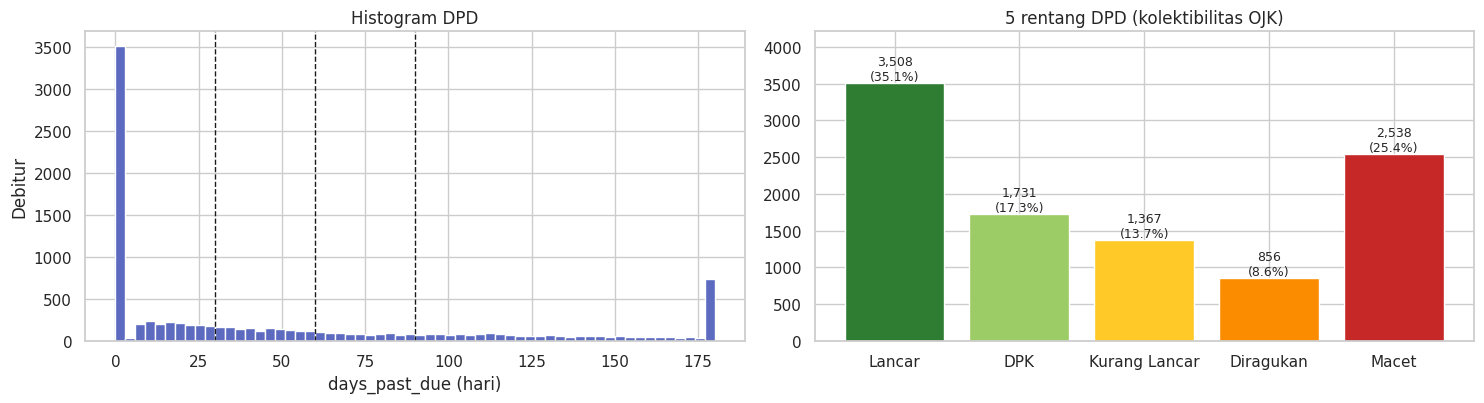

,count,mean,std,min,25%,50%,75%,max
days_past_due,10000.0,51.8,59.9,0.0,0.0,26.0,92.0,180.0


DPD = 0: 35.1% | DPD > 0 minimum: 5 hari


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
axes[0].hist(eda[TARGET], bins=60, color='#5c6bc0')
for b in [30, 60, 90]:
    axes[0].axvline(b, ls='--', c='k', lw=1)
axes[0].set_xlabel('days_past_due (hari)'); axes[0].set_ylabel('Debitur'); axes[0].set_title('Histogram DPD')
vc = eda['kelas'].value_counts().reindex(COLLECT_ORDER)
axes[1].bar(vc.index, vc.values, color=[PALETTE[c] for c in vc.index])
for i, v in enumerate(vc.values):
    axes[1].text(i, v + 40, f'{v:,}\n({v / len(eda):.1%})', ha='center', fontsize=9)
axes[1].set_ylim(0, vc.max() * 1.2); axes[1].set_title('5 rentang DPD (kolektibilitas OJK)')
plt.tight_layout(); plt.show()
display(eda[TARGET].describe().round(1).to_frame().T)
print('DPD = 0:', f"{(eda[TARGET] == 0).mean():.1%}", '| DPD > 0 minimum:', eda.loc[eda[TARGET] > 0, TARGET].min(), 'hari')

**Insight:**
* Rata-rata DPD **51,8 hari**, median 26, maksimum 180. **35,1% debitur ber-DPD 0**. DPD > 0 dimulai dari **5 hari**, karena tidak ada nilai 1–4.
* Distribusinya **condong ke nol dan bimodal**: menumpuk di 0 dan di 91–180 (Macet 25,4%).

**Implikasi:**
1. Split dan CV di-**stratify per rentang DPD**, supaya tiap fold punya proporsi Lancar–Macet yang sama.
2. MAE total bisa menutupi kesalahan di kelas tengah, jadi **MAE dilaporkan per rentang DPD**.
3. Model regresi jarang memprediksi tepat 0, sehingga **batas Lancar perlu disetel** (Bab 6C).

### 4.2 Tujuan pinjaman mana yang paling berisiko?

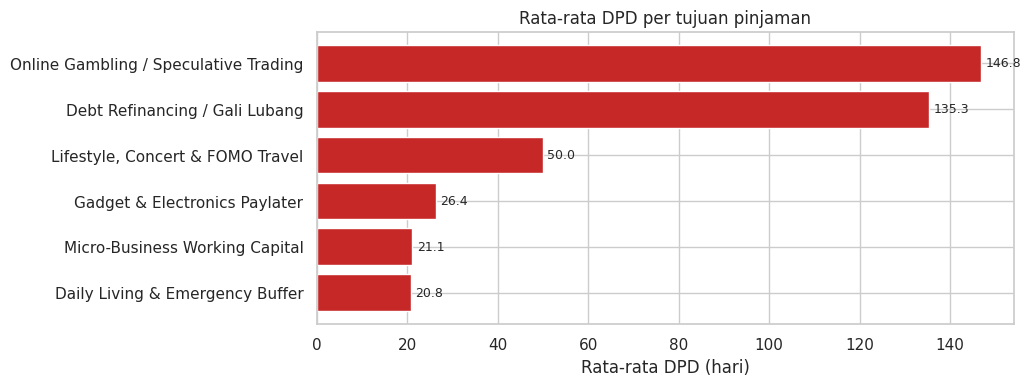

Kruskal-Wallis H = 4,500, p = 0.00e+00, ε² = 0.450


,mean,median,size
primary_loan_purpose,,,
Daily Living & Emergency Buffer,20.8,0.0,2473
Micro-Business Working Capital,21.1,0.0,794
Gadget & Electronics Paylater,26.4,9.0,2569
"Lifestyle, Concert & FOMO Travel",50.0,35.0,2207
Debt Refinancing / Gali Lubang,135.3,139.0,1400
Online Gambling / Speculative Trading,146.8,157.0,557


In [8]:
g = eda.groupby('primary_loan_purpose')[TARGET].agg(['mean', 'median', 'size']).sort_values('mean')
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(g.index, g['mean'], color='#c62828')
for i, v in enumerate(g['mean']):
    ax.text(v + 1, i, f'{v:.1f}', va='center', fontsize=9)
ax.set_xlabel('Rata-rata DPD (hari)'); ax.set_title('Rata-rata DPD per tujuan pinjaman'); plt.show()
h, p, e2 = kruskal('primary_loan_purpose')
print(f'Kruskal-Wallis H = {h:,.0f}, p = {p:.2e}, ε² = {e2:.3f}')
display(g.round(1))

**Insight:** tujuan pinjaman berhubungan **sangat kuat** dengan DPD (Kruskal-Wallis ε² **0,450**, efek besar).
* **Judi/spekulasi rata-rata 146,8 hari** (median 157) dan **gali lubang 135,3 hari** (median 139). Mayoritas debitur dengan tujuan ini sudah Macet.
* Lifestyle/FOMO 50,0 hari; gadget 26,4; modal usaha 21,1; kebutuhan harian 20,8.

**Implikasi bisnis:** meminjam untuk membayar pinjaman lain atau untuk berjudi adalah tanda *debt spiral*. Sinyal ini sudah ada **sebelum** debitur menunggak, sehingga tepat dipakai untuk peringatan dini.

### 4.3 Apakah multi-aplikasi menaikkan DPD?

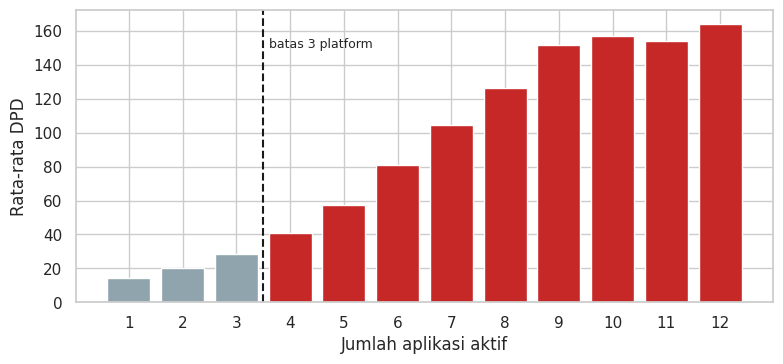

Spearman ρ = 0.593, p = 0.00e+00


,size,mean,median
num_active_lending_apps,,,
1-3,4735,22.8,0.0
4-8,4646,67.4,52.0
9-12,619,156.1,168.0


In [9]:
g = eda.groupby('num_active_lending_apps')[TARGET].agg(['mean', 'size'])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(g.index, g['mean'], color=['#90a4ae' if i <= 3 else '#c62828' for i in g.index])
ax.axvline(3.5, ls='--', c='k'); ax.text(3.6, 150, 'batas 3 platform', fontsize=9)
ax.set_xticks(g.index); ax.set_xlabel('Jumlah aplikasi aktif'); ax.set_ylabel('Rata-rata DPD'); plt.show()
rho, p = stats.spearmanr(eda['num_active_lending_apps'], eda[TARGET])
print(f'Spearman ρ = {rho:.3f}, p = {p:.2e}')
grp = pd.cut(eda['num_active_lending_apps'], [0, 3, 8, 12], labels=['1-3', '4-8', '9-12'])
display(eda.groupby(grp, observed=True)[TARGET].agg(['size', 'mean', 'median']).round(1))

**Insight:** semakin banyak aplikasi aktif, semakin tinggi DPD (Spearman ρ **0,593**).
* 1–3 aplikasi: rata-rata **22,8 hari** (median 0)
* 4–8 aplikasi: 67,4 hari
* 9–12 aplikasi: **156,1 hari**

**Implikasi bisnis:** batas 3 penyelenggara pindar sudah dicabut OJK (Sept 2026), tetapi data menunjukkan > 3 aplikasi tetap sinyal risiko kuat. Karena itu flag ini disebut **"indikator risiko multi-platform"**.

### 4.4 Di DSR berapa DPD melonjak?

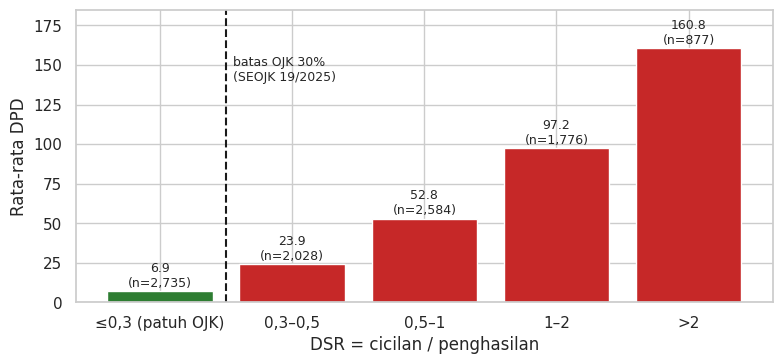

Spearman ρ (DSR vs DPD) = 0.773, p = 0.00e+00


,size,mean,median,% DPD>90
dsr_bucket,,,,
"≤0,3 (patuh OJK)",2735,6.9,0.0,1.1
"0,3–0,5",2028,23.9,8.0,8.6
"0,5–1",2584,52.8,39.0,23.7
1–2,1776,97.2,88.0,48.6
>2,877,160.8,180.0,97.7


In [10]:
bins = [0, 0.3, 0.5, 1, 2, np.inf]; labels = ['≤0,3 (patuh OJK)', '0,3–0,5', '0,5–1', '1–2', '>2']
eda['dsr_bucket'] = pd.cut(eda['debt_service_ratio'], bins, labels=labels)
g = eda.groupby('dsr_bucket', observed=True)[TARGET].agg(['size', 'mean', 'median'])
g['% DPD>90'] = eda.groupby('dsr_bucket', observed=True)[TARGET].apply(lambda s: (s > 90).mean() * 100)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(g.index.astype(str), g['mean'], color=['#2e7d32'] + ['#c62828'] * 4)
for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
    ax.text(i, m + 3, f'{m:.1f}\n(n={n:,})', ha='center', fontsize=9)
ax.axvline(0.5, ls='--', c='k'); ax.text(0.55, 140, 'batas OJK 30%\n(SEOJK 19/2025)', fontsize=9)
ax.set_ylim(0, 185); ax.set_ylabel('Rata-rata DPD'); ax.set_xlabel('DSR = cicilan / penghasilan'); plt.show()
rho, p = stats.spearmanr(eda['debt_service_ratio'], eda[TARGET])
print(f'Spearman ρ (DSR vs DPD) = {rho:.3f}, p = {p:.2e}')
display(g.round(1))

**Insight:** DSR adalah sinyal numerik **terkuat** (Spearman ρ **0,773**). DPD melonjak setelah melewati batas OJK 30%:

| DSR | Debitur | Rata-rata DPD | % DPD > 90 |
|---|---|---|---|
| ≤ 0,3 (patuh SEOJK 19/2025) | 2.735 | **6,9** | 1,1% |
| 0,3–0,5 | 2.028 | 23,9 | 8,6% |
| 0,5–1 | 2.584 | 52,8 | 23,7% |
| 1–2 | 1.776 | 97,2 | 48,6% |
| > 2 | 877 | **160,8** | 97,7% |

**Implikasi bisnis:** batas 30% OJK sangat cocok dengan pola data. Inilah dasar syarat simulator: sebuah opsi restrukturisasi baru disarankan jika **DSR after ≤ 30%**.

### 4.5 Berapa debitur yang tidak sesuai aturan OJK?
| Flag (1 = melanggar) | Aturan | Dasar | Produk |
|---|---|---|---|
| `flag_rate_above_ojk_cap` | Bunga > 0,3%/hari (tenor ≤ 6 bln) / > 0,2% (> 6 bln) | SEOJK 19/2023, SP OJK 214 | Pindar konsumtif |
| `flag_income_below_3jt` | Penghasilan < Rp3 juta | SP OJK 214 (pindar), PADK 2/2026 (paylater) | Pindar & paylater |
| `flag_apps_above_3` | > 3 platform aktif | PADK 2/2026 (paylater); batas pindar **dicabut Sept 2026** | Paylater; pindar = **indikator risiko multi-platform** |
| `flag_dsr_above_30` | Cicilan > 30% penghasilan | SEOJK 19/SEOJK.06/2025 | Pindar konsumtif (paylater 30% mulai 2029) |

,melanggar,% debitur,rata DPD (langgar),rata DPD (patuh),% DPD>90 (langgar),% DPD>90 (patuh)
flag_rate_above_ojk_cap,3340,33.4,55.6,49.8,30.7,22.7
flag_income_below_3jt,1731,17.3,50.5,52.0,25.2,25.4
flag_apps_above_3,5265,52.6,77.8,22.8,41.2,7.8
flag_dsr_above_30,7265,72.6,68.6,6.9,34.5,1.1


,debitur,rata_DPD,% DPD>90
n_pelanggaran,,,
0,739,1.1,0.0
1,3151,23.7,7.9
2,4099,59.5,27.4
3,1792,96.7,56.6
4,219,112.9,67.6


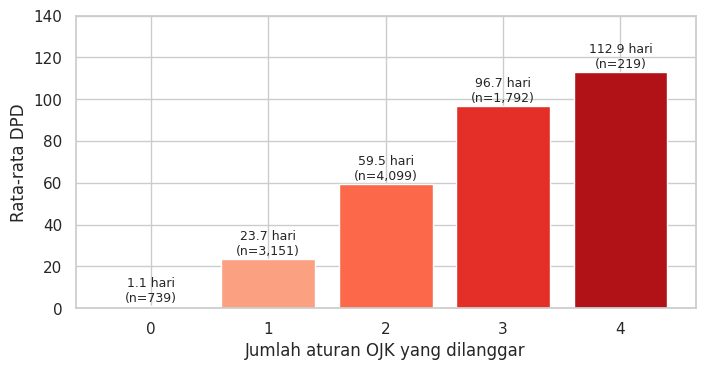

In [11]:
comp = pd.DataFrame({
    'melanggar': eda[FLAG_COLS].sum(),
    '% debitur': (eda[FLAG_COLS].mean() * 100).round(2),
    'rata DPD (langgar)': [eda.loc[eda[c] == 1, TARGET].mean() for c in FLAG_COLS],
    'rata DPD (patuh)': [eda.loc[eda[c] == 0, TARGET].mean() for c in FLAG_COLS],
    '% DPD>90 (langgar)': [(eda.loc[eda[c] == 1, TARGET] > 90).mean() * 100 for c in FLAG_COLS],
    '% DPD>90 (patuh)': [(eda.loc[eda[c] == 0, TARGET] > 90).mean() * 100 for c in FLAG_COLS],
}).round(1)
display(comp)
nv = eda.groupby('n_pelanggaran')[TARGET].agg(debitur='size', rata_DPD='mean')
nv['% DPD>90'] = eda.groupby('n_pelanggaran')[TARGET].apply(lambda s: (s > 90).mean() * 100)
display(nv.round(1))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(nv.index, nv['rata_DPD'], color=sns.color_palette('Reds', len(nv)))
for i, r in nv.iterrows():
    ax.text(i, r['rata_DPD'] + 2, f"{r['rata_DPD']:.1f} hari\n(n={int(r['debitur']):,})", ha='center', fontsize=9)
ax.set_ylim(0, 140); ax.set_xlabel('Jumlah aturan OJK yang dilanggar'); ax.set_ylabel('Rata-rata DPD'); plt.show()

**Insight:**
* Hanya **739 debitur (7,4%) patuh keempat aturan**, dengan rata-rata DPD **1,1 hari** dan 0% Macet. Rata-rata DPD naik konsisten: 1 pelanggaran **23,7** → 2 → **59,5** → 3 → **96,7** → 4 → **112,9 hari**.
* **DSR > 30%:** 72,6% debitur, rata-rata DPD 68,6 vs **6,9** pada yang patuh. Ini pembeda terkuat.
* **> 3 aplikasi:** 77,8 vs 22,8 hari. **Bunga di atas batas:** 55,6 vs 49,8 hari.
* **Penghasilan < Rp3 juta tidak membedakan DPD** (50,5 vs 52,0). Flag ini tetap ditampilkan sebagai label kepatuhan, tetapi **bukan sebagai faktor risiko**.

**Batasan:** tidak ada kolom jenis produk, sehingga flag dibaca sebagai indikator kepatuhan terhadap aturan yang relevan. DSR hanya dihitung dari utang yang tercatat di dataset.

### 4.6 Apakah DPD berbeda antar gender, provinsi, dan pekerjaan? (bekal uji keadilan)

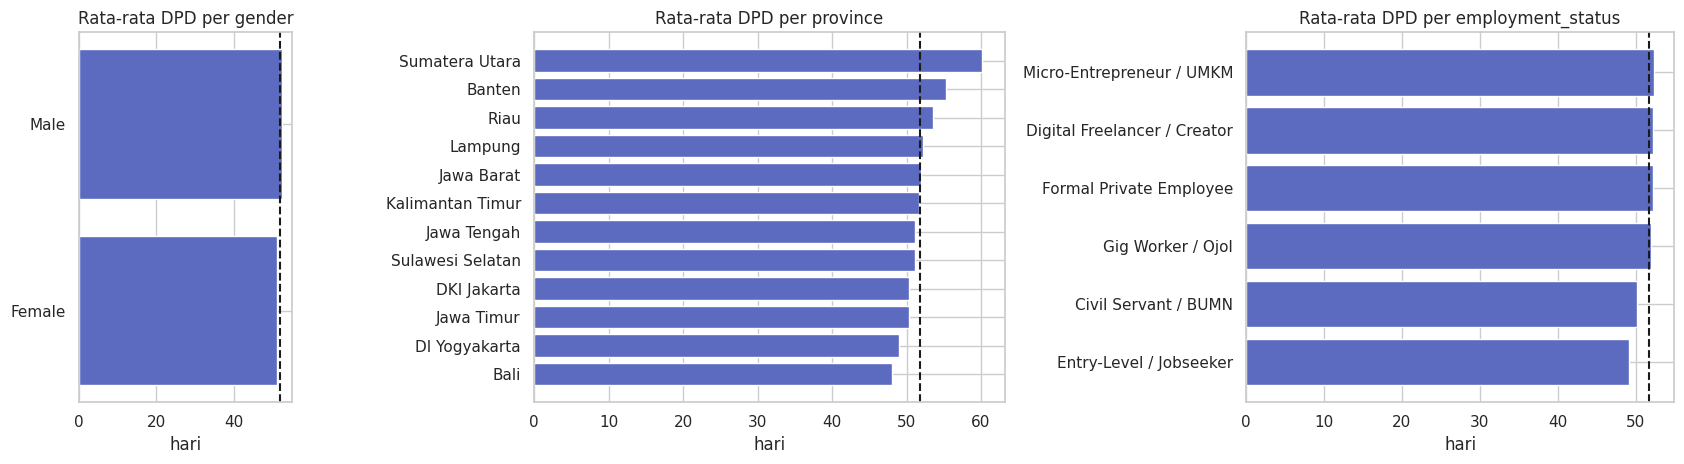

,kolom,H,p_value,ε²,rata DPD min,rata DPD maks
0,gender,1.8,0.1834,0.0001,51.1,52.4
1,province,19.0,0.0610,0.0008,48.1,60.2
2,employment_status,5.3,0.3839,0.0000,49.2,52.3


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1, 2.2, 2]})
rows = []
for ax, col in zip(axes, ['gender', 'province', 'employment_status']):
    s = eda.groupby(col)[TARGET].mean().sort_values()
    ax.barh(s.index, s.values, color='#5c6bc0'); ax.axvline(eda[TARGET].mean(), ls='--', c='k')
    ax.set_title(f'Rata-rata DPD per {col}'); ax.set_xlabel('hari')
    h, p, e2 = kruskal(col)
    rows.append({'kolom': col, 'H': round(h, 1), 'p_value': round(p, 4), 'ε²': round(e2, 4),
                 'rata DPD min': round(s.min(), 1), 'rata DPD maks': round(s.max(), 1)})
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows))

**Insight:** DPD **tidak berbeda signifikan** antar kelompok (semua p > 0,05, ε² ≤ 0,001):
* Gender: 51,1–52,4 hari
* Provinsi: 48,1–60,2 hari (p 0,061)
* Pekerjaan: 49,2–52,3 hari

**Implikasi:** DPD dasar antar kelompok setara. Kalau di Bab 8 error model berbeda antar kelompok, perbedaan itu berasal dari **model**, bukan dari data. Gender dan provinsi juga tidak dipakai sebagai fitur.

### 4.7 Bagaimana korelasi antar fitur numerik? (pengantar VIF)

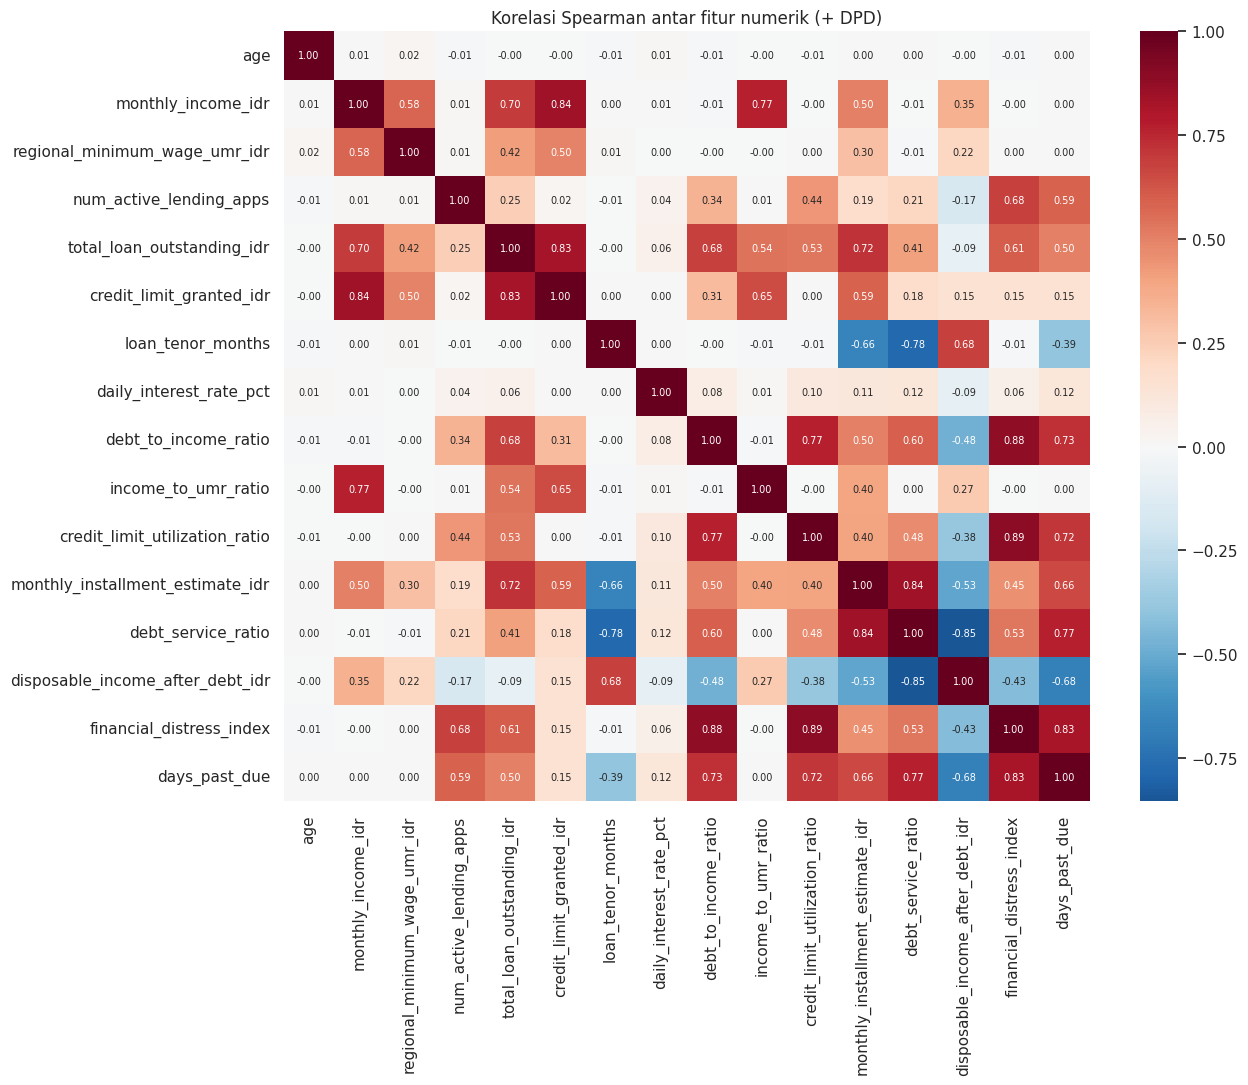

financial_distress_index            0.825
debt_service_ratio                  0.773
debt_to_income_ratio                0.731
credit_limit_utilization_ratio      0.715
disposable_income_after_debt_idr   -0.676
monthly_installment_estimate_idr    0.657
num_active_lending_apps             0.593
total_loan_outstanding_idr          0.504
loan_tenor_months                  -0.392
credit_limit_granted_idr            0.146
daily_interest_rate_pct             0.121
income_to_umr_ratio                 0.004
age                                 0.003
regional_minimum_wage_umr_idr       0.002
monthly_income_idr                  0.000
Name: ρ vs DPD, dtype: float64

In [13]:
num_cols = RAW_NUM + DERIVED_NUM + ['disposable_income_after_debt_idr', 'financial_distress_index', TARGET]
tmp = eda.copy(); tmp['disposable_income_after_debt_idr'] = df['disposable_income_after_debt_idr']; tmp['financial_distress_index'] = df['financial_distress_index']
corr = tmp[num_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax, annot_kws={'size': 7})
ax.set_title('Korelasi Spearman antar fitur numerik (+ DPD)'); plt.show()
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).rename('ρ vs DPD'))

**Insight:**
1. Korelasi tertinggi dengan DPD: `financial_distress_index` 0,825 (dibuang karena redundan), **DSR 0,773**, DTI 0,731, utilisasi 0,715, cicilan 0,657, aplikasi 0,593. Tenor −0,392, artinya tenor pendek berarti cicilan besar.
2. **Penghasilan, UMR, usia, dan penghasilan/UMR hampir nol** (|ρ| ≤ 0,004) terhadap DPD. Yang menentukan adalah **beban utang relatif terhadap penghasilan**, bukan besar penghasilannya.
3. Rasio-rasio turunan saling berkorelasi tinggi (DSR, DTI, utilisasi, cicilan). Ini pengantar ke audit VIF di Bab 5.2.

### 4.8 Apa beda profil debitur DPD 0 dan debitur menunggak? (landasan Model 2)

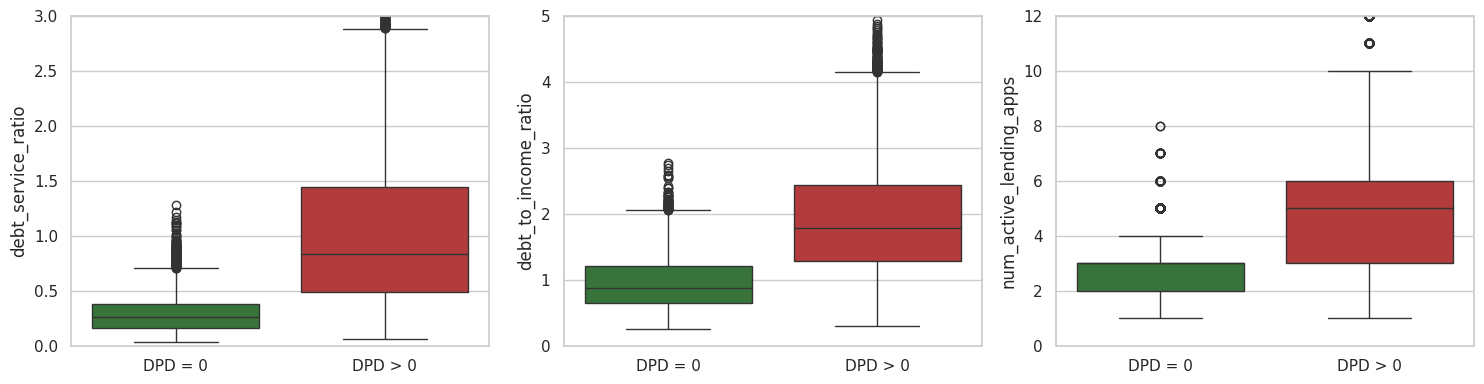

,fitur,median DPD=0,median DPD>0,p Mann-Whitney
0,debt_service_ratio,0.259,0.833,0.0
1,debt_to_income_ratio,0.884,1.783,0.0
2,num_active_lending_apps,3.000,5.000,0.0
3,credit_limit_utilization_ratio,0.404,0.659,0.0


In [14]:
eda['grup'] = np.where(eda[TARGET] == 0, 'DPD = 0', 'DPD > 0')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, lim in zip(axes, ['debt_service_ratio', 'debt_to_income_ratio', 'num_active_lending_apps'], [3, 5, 12]):
    sns.boxplot(data=eda, x='grup', y=col, ax=ax, palette=['#2e7d32', '#c62828'], order=['DPD = 0', 'DPD > 0'])
    ax.set_ylim(0, lim); ax.set_xlabel('')
plt.tight_layout(); plt.show()
rows = []
for col in ['debt_service_ratio', 'debt_to_income_ratio', 'num_active_lending_apps', 'credit_limit_utilization_ratio']:
    a, b = eda.loc[eda[TARGET] == 0, col], eda.loc[eda[TARGET] > 0, col]
    u, p = stats.mannwhitneyu(a, b)
    rows.append({'fitur': col, 'median DPD=0': round(a.median(), 3), 'median DPD>0': round(b.median(), 3), 'p Mann-Whitney': p})
display(pd.DataFrame(rows))

**Insight:** debitur menunggak berbeda nyata dari debitur DPD 0 (semua Mann-Whitney p ≈ 0):
* DSR median **0,83 vs 0,26**
* DTI 1,78 vs 0,88
* Aplikasi 5 vs 3
* Utilisasi 66% vs 40%

**Implikasi (landasan Model 2):** model yang dilatih pada semua debitur harus mempelajari dua hal sekaligus: (1) apakah debitur menunggak, dan (2) seberapa parah. Model 2 hanya dilatih pada debitur menunggak (DPD 5–180), sehingga seluruh kapasitasnya dipakai untuk membedakan **keparahan**. Itulah yang dibutuhkan simulator restrukturisasi.

### Ringkasan EDA
| Temuan | Dipakai di |
|---|---|
| 35,1% DPD = 0, bimodal | Stratify per rentang, MAE per rentang, penyetelan batas Lancar |
| DSR sinyal terkuat; batas 30% OJK memisahkan risiko (6,9 vs 68,6 hari) | Fitur model, flag, syarat simulator |
| > 3 aplikasi & tujuan judi/gali lubang = DPD tinggi | Fitur model, indikator risiko |
| Penghasilan sendiri tidak berhubungan dengan DPD | Tetap dipakai sebagai pembagi DSR |
| DPD dasar setara antar gender/provinsi/pekerjaan | Dasar uji keadilan |
| Rasio turunan saling berkorelasi | Audit VIF (Bab 5.2) |

## Bab 5 — Feature Engineering & Audit VIF (Zero Leakage)
### 5.1 Train-test split sebelum keputusan apa pun
* 80:20, **stratify per rentang DPD** (`dpd_to_collectibility(y)`). Tujuannya agar proporsi 5 rentang sama di train dan test, karena distribusi DPD condong ke 0 dan bimodal.
* `X` = **11 kolom mentah** (`RAW_INPUT`). Fitur turunan dihitung di dalam Pipeline. `gender` & `province` tidak masuk X dan disimpan di `g_test` untuk uji keadilan.

In [15]:
X = df[RAW_INPUT].copy(); y = df[TARGET].copy()
groups = df[['borrower_id', 'gender', 'province', 'employment_status']].copy()
strata = dpd_to_collectibility(y)
X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, groups, test_size=0.2, stratify=strata, random_state=RANDOM_STATE)
g_test[['borrower_id']].to_csv('model/test_ids.csv', index=False)
print('Train:', X_train.shape, '| Test:', X_test.shape, '| Train DPD>0 (data Model 2):', (y_train > 0).sum())
display(pd.DataFrame({'train %': pd.Series(dpd_to_collectibility(y_train)).value_counts(normalize=True) * 100,
                      'test %': pd.Series(dpd_to_collectibility(y_test)).value_counts(normalize=True) * 100}).loc[COLLECT_ORDER].round(2))

Train: (8000, 11) | Test: (2000, 11) | Train DPD>0 (data Model 2): 5194


,train %,test %
Lancar,35.08,35.10
DPK,17.31,17.30
Kurang Lancar,13.68,13.65
Diragukan,8.56,8.55
Macet,25.37,25.40


### 5.2 Audit multikolinearitas (VIF) di `X_train`
VIF (*Variance Inflation Factor*) mengukur seberapa besar satu fitur bisa ditebak dari fitur lain. VIF ≥ 10 berarti multikolinearitas berat: koefisien model linear menjadi tidak stabil dan sulit ditafsirkan. Seleksi dilakukan bertahap, dan setiap langkah punya alasan.

In [16]:
tr = add_features(X_train)
tr['disposable_income_after_debt_idr'] = df.loc[X_train.index, 'disposable_income_after_debt_idr']
tr['financial_distress_index'] = df.loc[X_train.index, 'financial_distress_index']

def vif(cols):
    Xc = add_constant(tr[cols].astype(float))
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=cols)

steps = {
    '0. Semua numerik (15)': RAW_NUM + DERIVED_NUM + ['disposable_income_after_debt_idr', 'financial_distress_index'],
    '1. − disposable_income, financial_distress_index': RAW_NUM + DERIVED_NUM,
    '2. − DTI, utilisasi limit': RAW_NUM + ['income_to_umr_ratio', 'monthly_installment_estimate_idr', 'debt_service_ratio'],
    '3. − income_to_umr, cicilan': RAW_NUM + ['debt_service_ratio'],
    '4. + 4 flag OJK (FINAL)': MODEL_NUM_COLS,
}
vif_tab = pd.DataFrame({k: vif(v) for k, v in steps.items()})
order = steps['0. Semua numerik (15)'] + FLAG_COLS
vif_tab = vif_tab.reindex(order)
fmt = vif_tab.map(lambda v: '' if pd.isna(v) else ('∞' if v > 1e6 else f'{v:.2f}'))
display(fmt)
print('VIF maks final:', round(vif_tab['4. + 4 flag OJK (FINAL)'].max(), 2))

,0. Semua numerik (15),"1. − disposable_income, financial_distress_index","2. − DTI, utilisasi limit","3. − income_to_umr, cicilan",4. + 4 flag OJK (FINAL)
age,1.00,1.00,1.00,1.00,1.00
monthly_income_idr,∞,19.67,16.00,4.69,5.28
regional_minimum_wage_umr_idr,6.31,6.31,6.31,1.72,1.73
num_active_lending_apps,15.68,1.42,1.28,1.26,2.73
total_loan_outstanding_idr,13.22,13.22,5.00,4.46,4.85
credit_limit_granted_idr,12.87,12.57,5.99,5.98,6.01
loan_tenor_months,1.57,1.57,1.50,1.48,2.35
daily_interest_rate_pct,1.04,1.03,1.02,1.02,2.29
debt_to_income_ratio,28.14,9.07,,,
income_to_umr_ratio,7.34,7.34,7.34,,


VIF maks final: 6.01


**Insight (VIF bertahap di `X_train`):**

| Langkah | Yang dibuang | Alasan | Efek |
|---|---|---|---|
| 0 | — | Semua 15 numerik | `monthly_income` & cicilan **∞** (karena `disposable` = pendapatan − cicilan), `financial_distress_index` ±105, DTI 28,1, utilisasi 20,7, aplikasi 15,7 |
| 1 | `disposable_income`, `financial_distress_index` | Identitas eksak & redundan (Bab 3.3) | ∞ hilang; tersisa penghasilan 19,7 dan pokok 13,2 |
| 2 | DTI, utilisasi limit | Rasio kolinear (pokok ÷ penghasilan / ÷ limit) | Pokok 5,0, limit 6,0; penghasilan masih 16,0 |
| 3 | `income_to_umr`, cicilan | Keduanya menaikkan VIF penghasilan | Penghasilan **4,69**; semua < 10 |
| 4 | + 4 flag OJK | Flag adalah fitur yang diminta proposal | VIF maks **6,01** (limit kredit) ✅ |

**Keputusan:** fitur numerik model = **8 kolom mentah + DSR + 4 flag** (13 kolom, `MODEL_NUM_COLS`). DTI, utilisasi, penghasilan/UMR, dan cicilan **tetap dihitung** untuk tampilan aplikasi, tetapi tidak masuk model.

### 5.3 Pipeline & pembungkus clipping

```
Pipeline([('features', FunctionTransformer(add_features)),     # rumus per baris (features.py)
          ('prep',     ColumnTransformer(...)),                 # fit hanya di data train
          ('reg',      ClippedRegressor(model))])               # prediksi di-clip ke [0, 180]
```

| Keputusan | Pilihan | Alasan |
|---|---|---|
| Fitur numerik | 13 kolom lolos VIF (`MODEL_NUM_COLS`) | Bab 5.2 |
| Encoding | `OrdinalEncoder` pendidikan; `OneHotEncoder(handle_unknown='ignore')` pekerjaan & tujuan | Pendidikan berurutan |
| Missing value | `SimpleImputer` (median / most_frequent) | Data bersih, tetapi input aplikasi bisa kosong |
| Scaling | `StandardScaler` untuk model linear/jarak; pohon tanpa scaling | Model linear/jarak sensitif skala |
| **Clipping** | `ClippedRegressor` membungkus model | Model linear bisa memprediksi DPD negatif. Clipping di dalam Pipeline membuat skor CV, tuning, test, aplikasi, dan Airflow memakai prediksi yang sama |
| Outlier, log1p, target log1p | **Diuji dengan CV** (5.4) | Diputuskan dari skor, bukan asumsi |

In [17]:
RUPIAH = ['monthly_income_idr', 'regional_minimum_wage_umr_idr', 'total_loan_outstanding_idr', 'credit_limit_granted_idr']

class CapP99(BaseEstimator, TransformerMixin):
    # Capping persentil ke-99 (dipelajari dari data latih fold) — hanya untuk uji 5.4
    def fit(self, X, y=None):
        self.hi_ = np.nanpercentile(np.asarray(X, dtype=float), 99, axis=0); return self
    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.hi_)

def build_prep(scale=True, cap=False, log_cols=(), num_cols=None):
    num_cols = MODEL_NUM_COLS if num_cols is None else num_cols
    plain = [c for c in num_cols if c not in log_cols]
    def num_pipe(log):
        s = [('imp', SimpleImputer(strategy='median'))]
        if cap: s.append(('cap', CapP99()))
        if log: s.append(('log', FunctionTransformer(np.log1p)))
        if scale: s.append(('sc', StandardScaler()))
        return Pipeline(s)
    tf = [('num', num_pipe(False), plain)]
    if log_cols: tf.append(('lognum', num_pipe(True), list(log_cols)))
    tf += [('edu', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                             ('enc', OrdinalEncoder(categories=[EDU_ORDER], handle_unknown='use_encoded_value', unknown_value=-1))]),
            ['education_level']),
           ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                             ('enc', OneHotEncoder(handle_unknown='ignore'))]), ['employment_status', 'primary_loan_purpose'])]
    return ColumnTransformer(tf)

def build_pipe(reg, **kw):
    return Pipeline([('features', FunctionTransformer(add_features)), ('prep', build_prep(**kw)), ('reg', ClippedRegressor(reg))])

# CV terstratifikasi per rentang DPD
def cv_splits(Xs, ys):
    return list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(Xs, dpd_to_collectibility(ys)))
CV1 = cv_splits(X_train, y_train)
X2_train, y2_train = X_train[y_train > 0], y_train[y_train > 0]
CV2 = cv_splits(X2_train, y2_train)

SCORING = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}

def cv_eval(name, pipe, Xs=X_train, ys=y_train, cv=None, oof_macet=False):
    cv = CV1 if cv is None else cv
    t = time.time()
    r = cross_validate(pipe, Xs, ys, cv=cv, scoring=SCORING, n_jobs=-1, return_train_score=True)
    row = {'model': name, 'MAE': -r['test_MAE'].mean(), 'MAE_std': r['test_MAE'].std(),
           'RMSE': -r['test_RMSE'].mean(), 'R2': r['test_R2'].mean(), 'MAE_train': -r['train_MAE'].mean()}
    if oof_macet:
        p = cross_val_predict(pipe, Xs, ys, cv=cv, n_jobs=-1)
        row['recall_Macet_OOF'] = ((p > 90)[ys.values > 90]).mean()
    row['detik'] = time.time() - t
    return row

def show(rows):
    return pd.DataFrame(rows).set_index('model').round(3)

### 5.4 Keputusan preprocessing berdasarkan CV

In [18]:
pre_rows = [
    cv_eval('LinReg — StandardScaler', build_pipe(LinearRegression())),
    cv_eval('LinReg — capping p99', build_pipe(LinearRegression(), cap=True)),
    cv_eval('LinReg — log1p rupiah', build_pipe(LinearRegression(), log_cols=RUPIAH)),
    cv_eval('LinReg — log1p rupiah + DSR', build_pipe(LinearRegression(), log_cols=RUPIAH + ['debt_service_ratio'])),
    cv_eval('LightGBM — target asli', build_pipe(LGBMRegressor(random_state=RANDOM_STATE, n_jobs=1, verbose=-1), scale=False)),
    cv_eval('LightGBM — target log1p', build_pipe(TransformedTargetRegressor(
        regressor=LGBMRegressor(random_state=RANDOM_STATE, n_jobs=1, verbose=-1), func=np.log1p, inverse_func=np.expm1), scale=False)),
    cv_eval('LightGBM — semua rasio (tanpa seleksi VIF)', build_pipe(LGBMRegressor(random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
                                                                   scale=False, num_cols=MODEL_NUM_COLS + ['debt_to_income_ratio', 'credit_limit_utilization_ratio', 'income_to_umr_ratio', 'monthly_installment_estimate_idr'])),
]
show(pre_rows)

,MAE,MAE_std,RMSE,R2,MAE_train,detik
model,,,,,,
LinReg — StandardScaler,12.605,0.170,17.315,0.917,12.562,1.032
LinReg — capping p99,12.060,0.177,16.590,0.924,12.019,0.756
LinReg — log1p rupiah,12.136,0.108,16.616,0.923,12.092,0.100
LinReg — log1p rupiah + DSR,11.204,0.127,15.634,0.932,11.162,0.096
LightGBM — target asli,8.476,0.096,12.383,0.957,6.421,0.433
LightGBM — target log1p,9.570,0.144,14.786,0.939,7.864,0.493
LightGBM — semua rasio (tanpa seleksi VIF),8.174,0.033,11.996,0.960,5.938,0.321


**Insight & keputusan:**

| Pertanyaan | Hasil CV (MAE) | Keputusan |
|---|---|---|
| Capping p99 (usulan proposal untuk model linear)? | LinReg 12,06 vs 12,61 | Membantu model linear, tetapi model pohon tidak terpengaruh outlier. Karena model final berbasis pohon (Bab 6), **tidak di-capping**. Nilai ekstrem seperti DSR > 2 adalah sinyal |
| log1p kolom rupiah / DSR? | LinReg 12,14 / **11,20** | Sama: hanya membantu model linear. **Tidak dipakai** di model final |
| Target `log1p(DPD)`? | LightGBM 9,57 vs **8,48** | **Target asli** (log memperburuk 1,1 hari, lebih dari 10× std) |
| Biaya seleksi VIF? | LightGBM semua rasio **8,17** vs fitur VIF 8,48 | Selisih 0,3 hari. **Tetap fitur VIF** karena fitur jadi lebih sedikit dan mudah dijelaskan. Model pohon sebenarnya tidak terganggu multikolinearitas; ini biaya kecil yang dicatat |

Baseline **Linear Regression** dilaporkan dengan StandardScaler biasa (MAE CV 12,61).

## Bab 6 — Pelatihan & Tuning (5-Fold CV terstratifikasi di `X_train`)
**Aturan memilih:** MAE CV terendah. Jika selisih < 1 std dianggap **seri**, dan dipilih model yang lebih sederhana/cepat. Untuk Model 1 ada syarat tambahan: **recall Macet (prediksi > 90) ≥ 0,90** di prediksi out-of-fold.

### 6A — Model 1: Prediksi Kelayakan (seluruh `X_train`)

In [19]:
def candidates():
    return {
        'Dummy (mean)':      (DummyRegressor(), True),
        'Linear Regression': (LinearRegression(), True),
        'Ridge':             (Ridge(), True),
        'Lasso':             (Lasso(alpha=0.1, max_iter=10000), True),
        'ElasticNet':        (ElasticNet(alpha=0.1, max_iter=10000), True),
        'KNN':               (KNeighborsRegressor(), True),
        'SVR (RBF)':         (SVR(C=50), True),
        'Decision Tree':     (DecisionTreeRegressor(random_state=RANDOM_STATE), False),
        'Random Forest':     (RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1), False),
        'AdaBoost':          (AdaBoostRegressor(random_state=RANDOM_STATE), False),
        'Gradient Boosting': (GradientBoostingRegressor(random_state=RANDOM_STATE), False),
        'XGBoost':       (XGBRegressor(random_state=RANDOM_STATE, n_jobs=1), False),
        'LightGBM':      (LGBMRegressor(random_state=RANDOM_STATE, n_jobs=1, verbose=-1), False),
    }
t0 = time.time()
m1_base = show([cv_eval(n, build_pipe(r, scale=s), oof_macet=True) for n, (r, s) in candidates().items()]).sort_values('MAE')
display(m1_base); print(f'{time.time() - t0:.0f} detik')

,MAE,MAE_std,RMSE,R2,MAE_train,recall_Macet_OOF,detik
model,,,,,,,
LightGBM,8.476,0.096,12.383,0.957,6.421,0.918,0.597
SVR (RBF),8.659,0.073,12.550,0.956,6.567,0.919,8.889
Random Forest,8.866,0.089,12.966,0.953,3.265,0.920,17.587
XGBoost,8.943,0.170,13.100,0.952,3.567,0.918,2.068
Gradient Boosting,9.007,0.068,12.858,0.954,8.371,0.927,3.346
Decision Tree,11.745,0.072,18.294,0.907,-0.000,0.889,0.221
Linear Regression,12.605,0.170,17.315,0.917,12.562,0.850,0.178
Ridge,12.608,0.171,17.317,0.917,12.565,0.848,0.191
Lasso,12.683,0.168,17.375,0.916,12.650,0.845,0.165


35 detik


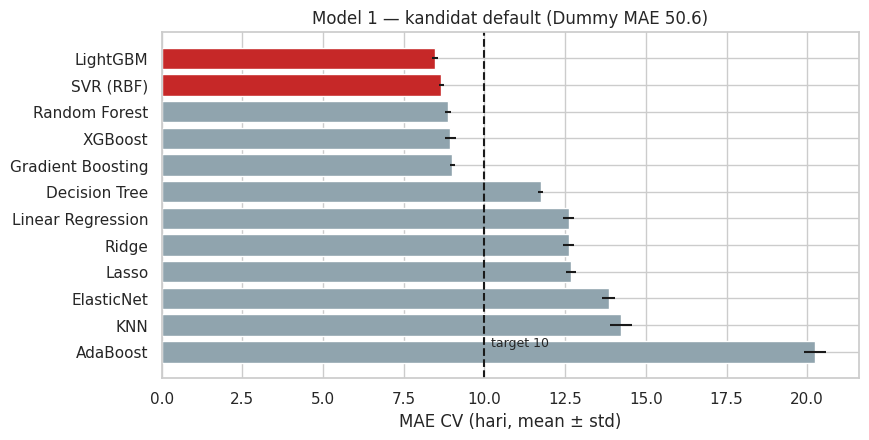

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.5))
b = m1_base.drop('Dummy (mean)').sort_values('MAE', ascending=False)
ax.barh(b.index, b['MAE'], xerr=b['MAE_std'], color=['#c62828' if i in b.index[-2:] else '#90a4ae' for i in b.index])
ax.axvline(10, ls='--', c='k'); ax.text(10.2, 0.2, 'target 10', fontsize=9)
ax.set_xlabel('MAE CV (hari, mean ± std)'); ax.set_title(f"Model 1 — kandidat default (Dummy MAE {m1_base.loc['Dummy (mean)', 'MAE']:.1f})"); plt.show()

**Insight (Model 1, default):**
1. Lima model mengalahkan target 10 hari bahkan tanpa tuning: **LightGBM 8,48**, SVR 8,66, Random Forest 8,87, XGBoost 8,97, Gradient Boosting 9,01.
2. Model linear jauh tertinggal (Linear Regression 12,61; Ridge/Lasso setara), karena hubungan DSR → DPD **tidak linear** (DPD melonjak setelah DSR > 1; Bab 4.4).
3. **Overfitting model pohon tanpa batas:** Decision Tree MAE train 0 vs CV 11,75; Random Forest 3,3 vs 8,9. LightGBM dan Gradient Boosting jauh lebih stabil.
4. Semua model kuat mencapai recall Macet OOF ≥ 0,90 (0,918–0,927). Model linear tidak (0,85).

**Dua teratas untuk tuning: LightGBM dan SVR (RBF).**

**Tuning 2 model teratas — `RandomizedSearchCV` (30 kombinasi, `scoring='neg_mean_absolute_error'`)**

Hyperparameter berada di dalam pembungkus clipping, sehingga prefix-nya `reg__regressor__`.

In [21]:
SPACES = {
    'LightGBM': (LGBMRegressor(random_state=RANDOM_STATE, n_jobs=1, verbose=-1), {
        'reg__regressor__n_estimators': randint(200, 900), 'reg__regressor__learning_rate': loguniform(0.01, 0.15),
        'reg__regressor__num_leaves': randint(8, 64), 'reg__regressor__min_child_samples': randint(5, 60),
        'reg__regressor__subsample': uniform(0.6, 0.4), 'reg__regressor__subsample_freq': [1],
        'reg__regressor__colsample_bytree': uniform(0.5, 0.5), 'reg__regressor__reg_lambda': loguniform(1e-3, 10)}),
    'Random Forest': (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1), {
        'reg__regressor__n_estimators': randint(150, 400), 'reg__regressor__max_depth': [10, 16, 22, None],
        'reg__regressor__min_samples_leaf': randint(1, 10), 'reg__regressor__max_features': ['sqrt', 0.5, 0.7, 1.0]}),
    'SVR (RBF)': (SVR(), {'reg__regressor__C': loguniform(5, 300), 'reg__regressor__gamma': loguniform(1e-3, 0.3),
                          'reg__regressor__epsilon': uniform(0.1, 3)}),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=RANDOM_STATE), {
        'reg__regressor__n_estimators': randint(150, 600), 'reg__regressor__learning_rate': loguniform(0.02, 0.2),
        'reg__regressor__max_depth': randint(2, 6), 'reg__regressor__subsample': uniform(0.6, 0.4),
        'reg__regressor__min_samples_leaf': randint(1, 30)}),
}
SCALE = {'LightGBM': False, 'Random Forest': False, 'SVR (RBF)': True, 'Gradient Boosting': False}

def tune(name, Xs, ys, cv, n_iter=30):
    reg, space = SPACES[name]
    t = time.time()
    s = RandomizedSearchCV(build_pipe(reg, scale=SCALE[name]), space, n_iter=n_iter, scoring=SCORING, refit='MAE',
                           cv=cv, n_jobs=-1, random_state=RANDOM_STATE, return_train_score=True).fit(Xs, ys)
    i = s.best_index_; r = s.cv_results_
    row = {'model': name + ' (tuned)', 'MAE': -r['mean_test_MAE'][i], 'MAE_std': r['std_test_MAE'][i],
           'RMSE': -r['mean_test_RMSE'][i], 'R2': r['mean_test_R2'][i], 'MAE_train': -r['mean_train_MAE'][i],
           'fit_s': r['mean_fit_time'][i], 'detik_search': time.time() - t}
    print(f'{name}: {time.time() - t:.0f} detik | best', {k.replace("reg__regressor__", ""): (round(v, 4) if isinstance(v, float) else v)
                                                       for k, v in s.best_params_.items()})
    return s, row

top2_m1 = [n for n in m1_base.index if n in SPACES][:2]
print('2 teratas Model 1:', top2_m1)
m1_search, m1_tuned_rows = {}, []
for n in top2_m1:
    m1_search[n], row = tune(n, X_train, y_train, CV1)
    oof = cross_val_predict(m1_search[n].best_estimator_, X_train, y_train, cv=CV1, n_jobs=-1)
    row['recall_Macet_OOF'] = ((oof > 90)[y_train.values > 90]).mean()
    m1_tuned_rows.append(row)
m1_tuned = show(m1_tuned_rows).sort_values('MAE'); display(m1_tuned)

2 teratas Model 1: ['LightGBM', 'SVR (RBF)']
LightGBM: 21 detik | best {'colsample_bytree': 0.8636, 'learning_rate': 0.0242, 'min_child_samples': 18, 'n_estimators': 451, 'num_leaves': 47, 'reg_lambda': 2.3886, 'subsample': 0.8989, 'subsample_freq': 1}
SVR (RBF): 93 detik | best {'C': 75.3416, 'epsilon': 1.0351, 'gamma': 0.0194}


,MAE,MAE_std,RMSE,R2,MAE_train,fit_s,detik_search,recall_Macet_OOF
model,,,,,,,,
LightGBM (tuned),8.366,0.084,12.237,0.958,5.569,0.694,21.043,0.923
SVR (RBF) (tuned),8.715,0.088,12.593,0.956,8.067,2.150,92.634,0.920


In [22]:
# Aturan memilih Model 1: MAE terendah; selisih < 1 std = seri -> lebih cepat; syarat recall Macet OOF >= 0,90
ok = m1_tuned[m1_tuned['recall_Macet_OOF'] >= 0.90]
ok = ok if len(ok) else m1_tuned   # fallback jika tidak ada yang lolos syarat
best = ok['MAE'].idxmin()
seri = ok[ok['MAE'] <= ok.loc[best, 'MAE'] + ok.loc[best, 'MAE_std']]
M1_NAME = seri['fit_s'].idxmin().replace(' (tuned)', '')
model1 = m1_search[M1_NAME].best_estimator_
print('Seri (selisih < 1 std):', list(seri.index))
print('MODEL 1 TERPILIH:', M1_NAME, '| gap MAE train vs CV:',
      round(m1_tuned.loc[M1_NAME + ' (tuned)', 'MAE'] - m1_tuned.loc[M1_NAME + ' (tuned)', 'MAE_train'], 2), 'hari')

Seri (selisih < 1 std): ['LightGBM (tuned)']
MODEL 1 TERPILIH: LightGBM | gap MAE train vs CV: 2.8 hari


**Insight:**
* **LightGBM tuned: MAE 8,37 ± 0,08**, RMSE 12,24, R² 0,958, recall Macet OOF 0,923.
* **SVR tuned: 8,72 ± 0,09**, tidak seri (selisih 0,35 hari, lebih dari 4× std). SVR juga 4× lebih lambat (fit 1,9 detik vs 0,5).
* Gap MAE train vs CV LightGBM **2,8 hari**: ada sedikit overfit, tetapi masih wajar dan CV-nya tetap terbaik.

**Keputusan: Model 1 = LightGBM.** Dipilih berdasarkan MAE CV terendah dan lolos syarat recall Macet sesuai proposal.

**Catatan deployment:** Library `lightgbm` perlu terpasang di container Airflow dan lingkungan aplikasi Streamlit.

### 6B — Model 2: Restrukturisasi Hutang (`X_train` dengan DPD > 0)

In [23]:
t0 = time.time()
cand2 = candidates()
m2_base = show([cv_eval(n, build_pipe(r, scale=s), X2_train, y2_train, CV2) for n, (r, s) in cand2.items()]).sort_values('MAE')
display(m2_base); print(f'{time.time() - t0:.0f} detik | baris latih Model 2: {len(X2_train):,}')

,MAE,MAE_std,RMSE,R2,MAE_train,detik
model,,,,,,
LightGBM,10.713,0.264,14.170,0.939,7.527,0.148
Random Forest,11.157,0.240,14.789,0.934,4.118,6.168
Gradient Boosting,11.225,0.313,14.727,0.934,10.232,0.765
SVR (RBF),11.280,0.214,14.686,0.935,8.034,1.935
XGBoost,11.428,0.188,15.079,0.931,3.460,0.209
Linear Regression,15.227,0.305,19.451,0.885,15.128,0.066
Ridge,15.231,0.306,19.453,0.885,15.132,0.066
Lasso,15.271,0.288,19.476,0.885,15.191,0.066
Decision Tree,15.434,0.324,21.006,0.866,-0.000,0.086


10 detik | baris latih Model 2: 5,194


In [24]:
top2_m2 = [n for n in m2_base.index if n in SPACES][:2]
print('2 teratas Model 2:', top2_m2)
m2_search, m2_tuned_rows = {}, []
for n in top2_m2:
    m2_search[n], row = tune(n, X2_train, y2_train, CV2)
    m2_tuned_rows.append(row)
m2_tuned = show(m2_tuned_rows).sort_values('MAE'); display(m2_tuned)
best = m2_tuned['MAE'].idxmin()
seri = m2_tuned[m2_tuned['MAE'] <= m2_tuned.loc[best, 'MAE'] + m2_tuned.loc[best, 'MAE_std']]
M2_NAME = seri['fit_s'].idxmin().replace(' (tuned)', '')
model2 = m2_search[M2_NAME].best_estimator_
print('Seri:', list(seri.index), '| MODEL 2 TERPILIH:', M2_NAME)

2 teratas Model 2: ['LightGBM', 'Random Forest']
LightGBM: 16 detik | best {'colsample_bytree': 0.8092, 'learning_rate': 0.0282, 'min_child_samples': 56, 'n_estimators': 704, 'num_leaves': 10, 'reg_lambda': 2.7527, 'subsample': 0.8721, 'subsample_freq': 1}
Random Forest: 74 detik | best {'max_depth': 22, 'max_features': 0.7, 'min_samples_leaf': 1, 'n_estimators': 285}


,MAE,MAE_std,RMSE,R2,MAE_train,fit_s,detik_search
model,,,,,,,
LightGBM (tuned),10.596,0.220,13.956,0.941,9.004,0.327,15.590
Random Forest (tuned),11.102,0.218,14.638,0.935,4.093,4.493,74.069


Seri: ['LightGBM (tuned)'] | MODEL 2 TERPILIH: LightGBM


**Insight (Model 2, 5.194 debitur DPD > 0):**
* Urutan default hampir sama: **LightGBM 10,71**, RF 11,16, GB 11,23, SVR 11,28. Linear Regression 15,23.
* Setelah tuning: **LightGBM 10,60 ± 0,22** vs RF 11,10 ± 0,22. LightGBM lebih baik (selisih 0,5 hari, lebih dari 2× std) dan 16× lebih cepat.
* RF tuned overfit berat (MAE train 4,1 vs CV 11,1). Gap LightGBM lebih kecil (9,0 vs 10,6) karena parameternya lebih konservatif (`num_leaves` 10, `min_child_samples` 56).

**Keputusan: Model 2 = LightGBM.** Margin terhadap target 12 hari sekitar **1,4 hari** (mengungguli Random Forest 11,10).

### 6C — Menyetel batas Lancar (out-of-fold Model 1)
Model regresi jarang memprediksi tepat 0, sehingga batas Lancar 0,5 hari terlalu ketat. Batas Lancar dicari di {0,5; 2; 4; 6; 8; 10; 12; 15} pada **prediksi out-of-fold** Model 1 di `X_train` (bukan test). Yang dipilih adalah batas dengan **macro F1 status 5 kelas** tertinggi, dengan syarat recall Macet ≥ 0,90. Batas 30/60/90 tetap mengikuti definisi OJK.

In [25]:
oof1 = cross_val_predict(model1, X_train, y_train, cv=CV1, n_jobs=-1)
y_cls_tr = dpd_to_collectibility(y_train)
rows = []
for t in [0.5, 2, 4, 6, 8, 10, 12, 15]:
    thr = dict(DEFAULT_THRESHOLDS, lancar=t); pc = dpd_to_collectibility(oof1, thr)
    rows.append({'batas_lancar': t, 'macro_F1_status': f1_score(y_cls_tr, pc, average='macro'),
                 'recall_Lancar': recall_score(y_cls_tr, pc, labels=['Lancar'], average='macro'),
                 'recall_DPK': recall_score(y_cls_tr, pc, labels=['DPK'], average='macro'),
                 'recall_Macet': recall_score(y_cls_tr, pc, labels=['Macet'], average='macro'),
                 '% prediksi Lancar': (pc == 'Lancar').mean() * 100})
thr_tab = pd.DataFrame(rows).set_index('batas_lancar').round(3); display(thr_tab)
ok = thr_tab[thr_tab['recall_Macet'] >= 0.90]
THR = dict(DEFAULT_THRESHOLDS, lancar=float(ok['macro_F1_status'].idxmax()))
print('BATAS TERPILIH:', THR, f"| % DPD asli = 0 di train: {(y_train == 0).mean():.1%}")

,macro_F1_status,recall_Lancar,recall_DPK,recall_Macet,% prediksi Lancar
batas_lancar,,,,,
0.5,0.620,0.384,0.810,0.923,13.638
2.0,0.660,0.561,0.775,0.923,20.475
4.0,0.684,0.702,0.722,0.923,26.338
6.0,0.695,0.794,0.661,0.923,30.662
8.0,0.696,0.846,0.599,0.923,33.700
10.0,0.694,0.891,0.534,0.923,36.562
12.0,0.688,0.921,0.466,0.923,39.000
15.0,0.670,0.954,0.351,0.923,42.425


BATAS TERPILIH: {'lancar': 8.0, 'dpk': 30, 'kurang_lancar': 60, 'diragukan': 90} | % DPD asli = 0 di train: 35.1%


**Insight:**
* Dengan batas 0,5 hari (definisi asli), hanya **13,6%** prediksi jatuh di Lancar, padahal 35,1% debitur aslinya ber-DPD 0. Akibatnya recall Lancar hanya 0,384.
* Macro F1 status naik dari **0,620 (batas 0,5) → 0,696 (batas 8)**. Batas 6 (0,695) dan 10 (0,694) praktis seri.
* Recall Macet tetap **0,923** di semua batas, karena batas Lancar tidak menyentuh batas 90.

**Keputusan: batas Lancar = 8 hari** (disimpan di `model_metadata.json`).

**Trade-off:** menaikkan batas Lancar membuat lebih banyak debitur DPK tergolong Lancar (recall DPK turun 0,81 → 0,60). Dampaknya kecil, karena keduanya berstatus **Layak** dan tindakannya hanya berbeda antara pemantauan dan pengingat otomatis.

## Bab 7 — Evaluasi di Test Set (sekali) & Simulasi Before vs After
### 7.1 Model 1 di test
Test dipakai **satu kali**. Tidak ada model, hyperparameter, fitur, atau batas status yang diubah setelah melihat angka ini.

In [26]:
p1 = predict_dpd(model1, X_test)
def reg_metrics(yt, yp):
    return {'MAE': mean_absolute_error(yt, yp), 'RMSE': np.sqrt(mean_squared_error(yt, yp)), 'R2': r2_score(yt, yp)}
base_dummy = predict_dpd(build_pipe(DummyRegressor()).fit(X_train, y_train), X_test)
base_lin = predict_dpd(build_pipe(LinearRegression()).fit(X_train, y_train), X_test)
i = m1_search[M1_NAME].best_index_; r = m1_search[M1_NAME].cv_results_
m1_test = pd.DataFrame({'Model 1 (test)': reg_metrics(y_test, p1),
                        'Model 1 (CV)': {'MAE': -r['mean_test_MAE'][i], 'RMSE': -r['mean_test_RMSE'][i], 'R2': r['mean_test_R2'][i]},
                        'Linear Regression (test)': reg_metrics(y_test, base_lin),
                        'Dummy (test)': reg_metrics(y_test, base_dummy),
                        'Target': {'MAE': 10, 'RMSE': 15, 'R2': np.nan}}).T.round(3)
display(m1_test)
rng = np.random.default_rng(RANDOM_STATE)
boot = np.array([[mean_absolute_error(y_test.values[ix], p1[ix]), np.sqrt(mean_squared_error(y_test.values[ix], p1[ix]))]
                 for ix in (rng.integers(0, len(p1), len(p1)) for _ in range(1000))])
print(f"Bootstrap 95% CI -> MAE {np.percentile(boot[:, 0], 2.5):.2f}–{np.percentile(boot[:, 0], 97.5):.2f} | "
      f"RMSE {np.percentile(boot[:, 1], 2.5):.2f}–{np.percentile(boot[:, 1], 97.5):.2f}")

,MAE,RMSE,R2
Model 1 (test),8.471,12.286,0.957
Model 1 (CV),8.366,12.237,0.958
Linear Regression (test),13.064,17.692,0.911
Dummy (test),50.251,59.270,-0.000
Target,10.000,15.000,NaN


Bootstrap 95% CI -> MAE 8.11–8.88 | RMSE 11.80–12.83


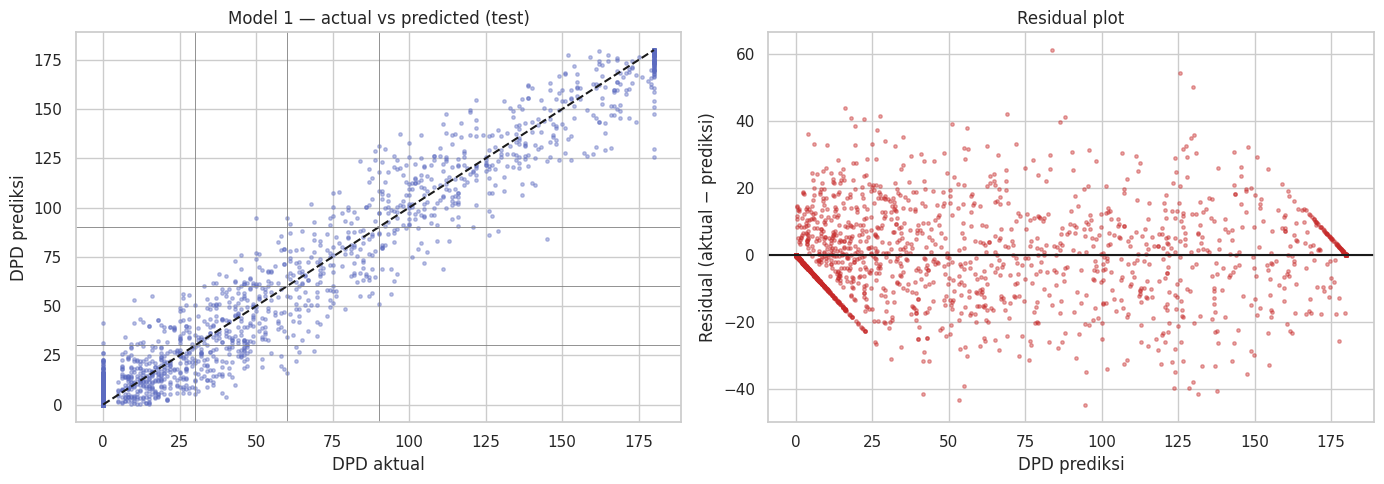

MAE per rentang DPD (Model 1, test):


,n,MAE,bias (aktual−pred),% |error| ≤ 15
kelas,,,,
Lancar,702.0,3.73,-3.73,95.01
DPK,346.0,8.65,-0.74,82.08
Kurang Lancar,273.0,13.20,3.09,61.17
Diragukan,171.0,14.23,2.15,56.73
Macet,508.0,10.42,2.32,74.41


In [27]:
res1 = y_test.values - p1
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, p1, s=6, alpha=0.4, c='#5c6bc0'); axes[0].plot([0, 180], [0, 180], 'k--')
for b in [30, 60, 90]:
    axes[0].axvline(b, c='grey', lw=0.6); axes[0].axhline(b, c='grey', lw=0.6)
axes[0].set_xlabel('DPD aktual'); axes[0].set_ylabel('DPD prediksi'); axes[0].set_title('Model 1 — actual vs predicted (test)')
axes[1].scatter(p1, res1, s=6, alpha=0.4, c='#c62828'); axes[1].axhline(0, c='k')
axes[1].set_xlabel('DPD prediksi'); axes[1].set_ylabel('Residual (aktual − prediksi)'); axes[1].set_title('Residual plot')
plt.tight_layout(); plt.show()

def per_range(yt, yp):
    k = pd.Series(dpd_to_collectibility(yt), index=yt.index)
    t = pd.DataFrame({'aktual': yt, 'pred': yp, 'kelas': k})
    out = t.groupby('kelas').apply(lambda d: pd.Series({'n': len(d), 'MAE': mean_absolute_error(d['aktual'], d['pred']),
                                                         'bias (aktual−pred)': (d['aktual'] - d['pred']).mean(),
                                                         '% |error| ≤ 15': (np.abs(d['aktual'] - d['pred']) <= 15).mean() * 100}))
    return out.reindex([c for c in COLLECT_ORDER if c in out.index]).round(2)
print('MAE per rentang DPD (Model 1, test):'); display(per_range(y_test, p1))

**Insight (test, dipakai sekali):**

| Metrik | Test | CV | Target | Status |
|---|---|---|---|---|
| MAE | **8,47 hari** (CI 95% 8,11–8,88) | 8,37 | ≤ 10 | ✅ |
| RMSE | **12,29 hari** (CI 11,80–12,83) | 12,24 | ≤ 15 | ✅ |
| R² | 0,957 | 0,958 | — | — |
| vs Linear Regression | 13,06 | | dikalahkan | ✅ |
| vs Dummy | 50,25 | | dikalahkan | ✅ |

* Test **sangat dekat dengan CV** (selisih 0,1 hari), jadi tidak ada tanda overfit pada proses tuning.
* **MAE per rentang:** Lancar 3,7 · DPK 8,7 · **Kurang Lancar 13,2 · Diragukan 14,2** · Macet 10,4. Kelas tengah paling sulit, karena perbedaan 30 vs 31 hari tidak terlihat dari profil utang.
* **Bias:** model sedikit **melebih-lebihkan** DPD debitur Lancar (−3,7 hari) dan sedikit **meremehkan** kelas tengah (+2–3 hari). Ini pola regresi ke rata-rata yang umum.

**Implikasi bisnis:** untuk 95% debitur Lancar dan 74% debitur Macet, error ≤ 15 hari. Di kelas tengah hanya 57–61%, jadi prediksi di rentang 31–90 sebaiknya dibaca sebagai **"perlu perhatian"**, bukan angka hari yang pasti.

### 7.2 Pemetaan prediksi DPD ke status (pelengkap)

               precision    recall  f1-score   support

       Lancar      0.880     0.839     0.859       702
          DPK      0.534     0.630     0.578       346
Kurang Lancar      0.618     0.546     0.580       273
    Diragukan      0.577     0.567     0.572       171
        Macet      0.934     0.945     0.939       508

     accuracy                          0.766      2000
    macro avg      0.709     0.705     0.706      2000
 weighted avg      0.772     0.766     0.768      2000



,test
macro F1 status (5 kelas),0.7058
recall Macet (prediksi > 90),0.9449
akurasi ±1 kelas,0.9940
akurasi status kelayakan (3),0.9015


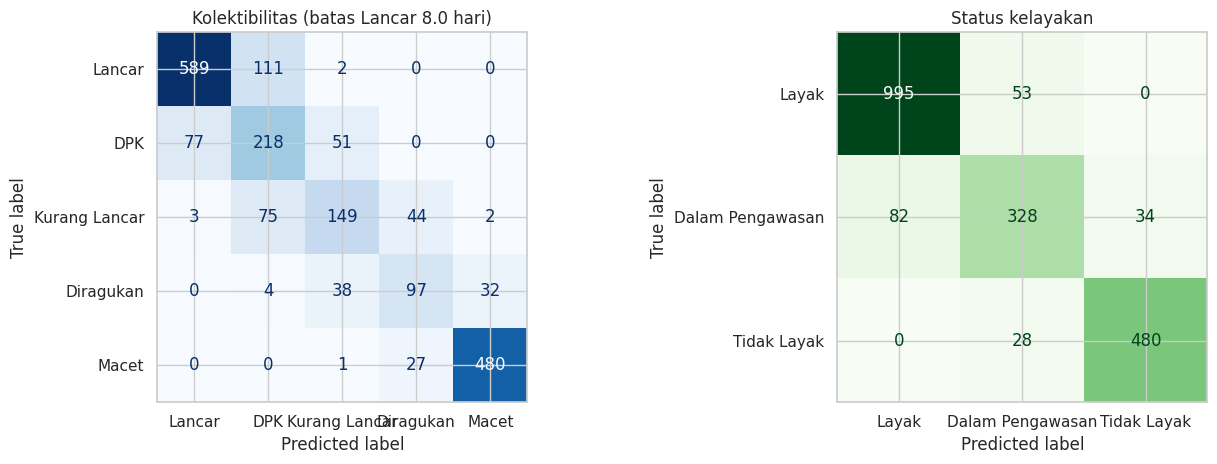

In [28]:
yc_test = dpd_to_collectibility(y_test); pc_test = dpd_to_collectibility(p1, THR)
print(classification_report(yc_test, pc_test, labels=COLLECT_ORDER, digits=3))
ordm = {c: i for i, c in enumerate(COLLECT_ORDER)}
within1 = (np.abs(pd.Series(pc_test).map(ordm).values - pd.Series(yc_test).map(ordm).values) <= 1).mean()
status_scores = {'macro F1 status (5 kelas)': f1_score(yc_test, pc_test, average='macro'),
                 'recall Macet (prediksi > 90)': recall_score(yc_test, pc_test, labels=['Macet'], average='macro'),
                 'akurasi ±1 kelas': within1,
                 'akurasi status kelayakan (3)': (dpd_to_eligibility(p1, THR) == dpd_to_eligibility(y_test)).mean()}
display(pd.Series(status_scores).round(4).to_frame('test'))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ConfusionMatrixDisplay(confusion_matrix(yc_test, pc_test, labels=COLLECT_ORDER), display_labels=COLLECT_ORDER).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f"Kolektibilitas (batas Lancar {THR['lancar']} hari)")
ConfusionMatrixDisplay(confusion_matrix(dpd_to_eligibility(y_test), dpd_to_eligibility(p1, THR), labels=ELIG_ORDER),
                       display_labels=ELIG_ORDER).plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title('Status kelayakan'); plt.tight_layout(); plt.show()

**Insight (pemetaan status, pelengkap):**
* **Recall Macet 0,945** (target ≥ 0,90 ✅). Presisi Macet 0,934, jadi debitur yang diprediksi Macet hampir semuanya benar Macet.
* **Akurasi ±1 kelas 99,4%:** salah kelas hampir selalu ke kelas tetangga.
* Macro F1 status 0,706. Kelas tengah (F1 0,57–0,58) lebih lemah dari Lancar (0,86) dan Macet (0,94).
* **Akurasi status kelayakan (3 status) 90,2%.** Status inilah yang dipakai tim collection untuk memilih tindakan.

**Catatan:** model tidak dilatih untuk kelas. Kelas hanya hasil pemetaan prediksi DPD, sesuai proposal v5.

### 7.3 Model 2 di test (debitur test dengan DPD > 0)

In [29]:
X2_test, y2_test = X_test[y_test > 0], y_test[y_test > 0]
p2 = predict_dpd(model2, X2_test)
lin2 = predict_dpd(build_pipe(LinearRegression()).fit(X2_train, y2_train), X2_test)
dum2 = predict_dpd(build_pipe(DummyRegressor()).fit(X2_train, y2_train), X2_test)
i2 = m2_search[M2_NAME].best_index_; r2_ = m2_search[M2_NAME].cv_results_
m2_test = pd.DataFrame({'Model 2 (test)': reg_metrics(y2_test, p2),
                        'Model 2 (CV)': {'MAE': -r2_['mean_test_MAE'][i2], 'RMSE': -r2_['mean_test_RMSE'][i2], 'R2': r2_['mean_test_R2'][i2]},
                        'Linear Regression (test)': reg_metrics(y2_test, lin2), 'Dummy (test)': reg_metrics(y2_test, dum2),
                        'Target': {'MAE': 12, 'RMSE': np.nan, 'R2': np.nan}}).T.round(3)
display(m2_test); print(f'n test Model 2: {len(y2_test):,}')
print('MAE per rentang DPD (Model 2, test):'); display(per_range(y2_test, p2))

,MAE,RMSE,R2
Model 2 (test),10.680,13.953,0.940
Model 2 (CV),10.596,13.956,0.941
Linear Regression (test),15.546,19.931,0.877
Dummy (test),49.517,56.770,-0.000
Target,12.000,NaN,NaN


n test Model 2: 1,298
MAE per rentang DPD (Model 2, test):


,n,MAE,bias (aktual−pred),% |error| ≤ 15
kelas,,,,
DPK,346.0,9.01,-6.90,82.66
Kurang Lancar,273.0,11.27,1.57,69.96
Diragukan,171.0,14.37,3.13,56.73
Macet,508.0,10.26,2.21,75.39


**Insight (Model 2, 1.298 debitur test dengan DPD > 0):**
* **MAE 10,68 hari** (target ≤ 12 ✅), RMSE 13,95, R² 0,940. Hasil ini mengalahkan Linear Regression (15,55) dan Dummy (49,52), dan dekat dengan CV (10,60).
* MAE per rentang: DPK 9,0 · Kurang Lancar 11,3 · Diragukan 14,4 · Macet 10,3.
* Bias DPK −6,9 hari: Model 2 tidak pernah melihat debitur DPD 0, sehingga prediksinya untuk debitur ringan cenderung lebih tinggi. Inilah alasan status "after" terbaik yang realistis adalah **DPK** (lihat 7.4).

### 7.4 Simulasi restrukturisasi Before vs After (debitur test dengan prediksi DPD 31–90)
Alurnya (`features.simulate_restructuring`):
1. Untuk tiap tenor **lebih panjang** dari tenor sekarang: bunga = `min(bunga awal, batas OJK)`, cicilan dan DSR dihitung ulang, lalu Model 2 memprediksi DPD *after*.
2. **Opsi disarankan** = opsi pertama dengan **DSR ≤ 30% dan prediksi DPD after ≤ 30 hari**.
3. Jika tidak ada opsi → **"perlu penanganan lain"** + pokok maksimum OJK (DSR tepat 30% pada tenor 24 bulan), lalu skenario "tenor 24 + pokok disesuaikan" diprediksi ulang dengan Model 2.

In [30]:
t0 = time.time()
mask_mid = (p1 > 30) & (p1 <= 90)
sim_X = X_test[mask_mid]
recs = []
for idx in sim_X.index:
    row = X_test.loc[[idx]]
    s = simulate_restructuring(row, model2, THR)
    f = add_features(row).iloc[0]
    rec = {'idx': idx, 'dpd_aktual': y_test[idx], 'dpd_before': p1[X_test.index.get_loc(idx)], 'dsr_before': f['debt_service_ratio'],
           'tenor_before': f['loan_tenor_months'], 'punya_opsi': not s['need_other'],
           'ada_tenor_dsr_ok': bool(len(s['options']) and s['options']['dsr_sesuai_ojk'].any())}
    if s['best'] is not None:
        rec.update(tenor_after=s['best']['tenor_bulan'], dsr_after=s['best']['dsr'], dpd_after=s['best']['pred_dpd_after'],
                   kolek_after=s['best']['kolektibilitas_after'], potongan_pct=0.0, kelebihan_pokok=0)
    else:
        h = s['haircut']
        rec.update(tenor_after=24, dsr_after=h['dsr'], dpd_after=h['pred_dpd_after'], kolek_after=h['kolektibilitas_after'],
                   potongan_pct=h['potongan_pct'], kelebihan_pokok=h['kelebihan_pokok_idr'])
    recs.append(rec)
SIM = pd.DataFrame(recs).set_index('idx')
SIM['kolek_before'] = dpd_to_collectibility(SIM['dpd_before'], THR)
print(f'Debitur test dengan prediksi DPD 31–90: {len(SIM):,} | waktu {time.time() - t0:.0f} detik')
port = pd.DataFrame({
    'Before': {'rata-rata prediksi DPD': SIM['dpd_before'].mean(), 'rata-rata DSR': SIM['dsr_before'].mean(),
               '% DSR ≤ 30%': (SIM['dsr_before'] <= DSR_CAP).mean() * 100, '% prediksi DPD ≤ 30': (SIM['dpd_before'] <= 30).mean() * 100},
    'After (opsi disarankan / skenario pokok)': {'rata-rata prediksi DPD': SIM['dpd_after'].mean(), 'rata-rata DSR': SIM['dsr_after'].mean(),
               '% DSR ≤ 30%': (SIM['dsr_after'] <= DSR_CAP + 1e-9).mean() * 100, '% prediksi DPD ≤ 30': (SIM['dpd_after'] <= 30).mean() * 100}}).round(2)
display(port)
print(f"Punya opsi tenor aman (DSR ≤ 30% & DPD after ≤ 30): {SIM['punya_opsi'].mean():.1%} ({SIM['punya_opsi'].sum()})")
print(f"Perlu penanganan lain                         : {(~SIM['punya_opsi']).mean():.1%} ({(~SIM['punya_opsi']).sum()})")
no = SIM[~SIM['punya_opsi']]
print(f"  -> di antaranya sebenarnya bisa DSR ≤ 30% dengan tenor lebih panjang: {no['ada_tenor_dsr_ok'].mean():.1%}")
print(f"  -> butuh potongan pokok (DSR > 30% di tenor 24): {(no['potongan_pct'] > 0).sum()} debitur, median potongan {no.loc[no['potongan_pct'] > 0, 'potongan_pct'].median():.1f}%")
display(pd.crosstab(SIM['kolek_before'], SIM['kolek_after'], margins=True).reindex(columns=[c for c in COLLECT_ORDER if c in SIM['kolek_after'].unique()] + ['All']))
display(SIM.groupby('tenor_after').size().rename('debitur (tenor after)').to_frame().T)

Debitur test dengan prediksi DPD 31–90: 409 | waktu 24 detik


,Before,After (opsi disarankan / skenario pokok)
rata-rata prediksi DPD,55.69,24.84
rata-rata DSR,0.91,0.24
% DSR ≤ 30%,4.16,100.00
% prediksi DPD ≤ 30,0.00,78.97


Punya opsi tenor aman (DSR ≤ 30% & DPD after ≤ 30): 78.7% (322)
Perlu penanganan lain                         : 21.3% (87)
  -> di antaranya sebenarnya bisa DSR ≤ 30% dengan tenor lebih panjang: 92.0%
  -> butuh potongan pokok (DSR > 30% di tenor 24): 7 debitur, median potongan 5.8%


kolek_after,Lancar,DPK,Kurang Lancar,Diragukan,All
kolek_before,,,,,
Diragukan,1,105,47,15,168
Kurang Lancar,12,205,24,0,241
All,13,310,71,15,409


tenor_after,3,6,9,12,18,24
debitur (tenor after),8,97,115,37,50,102


In [31]:
# Profil: apa beda debitur yang punya opsi vs perlu penanganan lain?
prof = add_features(X_test.loc[SIM.index]).assign(punya_opsi=SIM['punya_opsi'])
display(prof.groupby('punya_opsi')[['num_active_lending_apps', 'debt_service_ratio', 'debt_to_income_ratio', 'loan_tenor_months',
                                     'monthly_income_idr']].median().round(2))
display((pd.crosstab(prof['punya_opsi'], prof['primary_loan_purpose'], normalize='index') * 100).round(1))

# Contoh tabel Before vs After untuk 1 debitur yang punya opsi dan 1 yang perlu penanganan lain
for flag in [True, False]:
    idx = SIM.index[SIM['punya_opsi'] == flag][0]
    row = X_test.loc[[idx]]; s = simulate_restructuring(row, model2, THR)
    print(f"\n{g_test.loc[idx, 'borrower_id']} | DPD aktual {y_test[idx]} | {'punya opsi' if flag else SIM_NO_OPTION}")
    display(s['options']); display(before_after_table(row, model1, s, THR))
print('\nDisclaimer:', SIM_DISCLAIMER)

,num_active_lending_apps,debt_service_ratio,debt_to_income_ratio,loan_tenor_months,monthly_income_idr
punya_opsi,,,,,
False,6.0,0.46,1.88,6.0,5090000.0
True,4.0,1.01,1.50,1.0,5220000.0


primary_loan_purpose,Daily Living & Emergency Buffer,Debt Refinancing / Gali Lubang,Gadget & Electronics Paylater,"Lifestyle, Concert & FOMO Travel",Micro-Business Working Capital,Online Gambling / Speculative Trading
punya_opsi,,,,,,
False,1.1,39.1,16.1,37.9,0.0,5.7
True,23.9,0.0,31.4,35.4,9.3,0.0



ID_DEB_BFE0846FAD | DPD aktual 64 | punya opsi


,tenor_bulan,bunga_harian_pct,cicilan_bulanan_idr,dsr,dsr_sesuai_ojk,pred_dpd_after,kolektibilitas_after,memenuhi_syarat
0,3,0.23,2096157,0.6023,False,12.4,DPK,False
1,6,0.23,1227823,0.3528,False,8.9,DPK,False
2,9,0.20,891489,0.2562,True,8.9,DPK,True
3,12,0.20,746767,0.2146,True,8.9,DPK,True
4,18,0.20,602044,0.1730,True,9.6,DPK,True
5,24,0.20,529683,0.1522,True,9.6,DPK,True


,Before,After (tenor disarankan)
Tenor (bulan),1,9
Bunga harian (%),0.23,0.2
Pokok (Rp),5210000,5210000
Cicilan bulanan (Rp),5569490,891489
DSR,160.0%,25.6%
Prediksi DPD (hari),54.6,8.9
Kolektibilitas,Kurang Lancar,DPK
Status,Dalam Pengawasan,Layak



ID_DEB_A8BD2F0773 | DPD aktual 50 | Perpanjangan tenor tidak cukup — perlu penanganan lain (keringanan pokok/bunga atau eskalasi ke tim collection).


,tenor_bulan,bunga_harian_pct,cicilan_bulanan_idr,dsr,dsr_sesuai_ojk,pred_dpd_after,kolektibilitas_after,memenuhi_syarat
0,6,0.23,904960,0.2855,True,60.0,Kurang Lancar,False
1,9,0.20,657067,0.2073,True,57.4,Kurang Lancar,False
2,12,0.20,550400,0.1736,True,54.9,Kurang Lancar,False
3,18,0.20,443733,0.1400,True,57.6,Kurang Lancar,False
4,24,0.20,390400,0.1232,True,57.6,Kurang Lancar,False


,Before,After (tenor 24 + pokok disesuaikan)*
Tenor (bulan),3,24
Bunga harian (%),0.23,0.2
Pokok (Rp),3840000,3840000
Cicilan bulanan (Rp),1544960,390400
DSR,48.7%,12.3%
Prediksi DPD (hari),76.8,57.6
Kolektibilitas,Diragukan,Kurang Lancar
Status,Dalam Pengawasan,Dalam Pengawasan



Disclaimer: Simulasi menunjukkan perubahan prediksi model jika tenor atau pokok diubah. Model mempelajari pola dari data, bukan hubungan sebab-akibat, sehingga hasil simulasi bukan jaminan debitur akan membayar. Keputusan keringanan pokok tetap memerlukan persetujuan manajemen.


**Insight (409 debitur test dengan prediksi DPD 31–90):**

| | Before | After |
|---|---|---|
| Rata-rata prediksi DPD | **55,7 hari** | **24,8 hari** |
| Rata-rata DSR | 91% | 24% |
| % DSR ≤ 30% | 4,2% | 100% |
| % prediksi DPD ≤ 30 | 0% | 79,0% |

1. **78,7% (322 debitur) punya opsi tenor aman** (DSR ≤ 30% dan DPD after ≤ 30). Di antara mereka, tenor yang disarankan paling sering **6–9 bulan** (212 dari 322) dan hanya 15 yang butuh 24 bulan. Termasuk skenario pokok, **323 debitur** (79,0%) diprediksi berstatus Layak setelah restrukturisasi (310 DPK, 13 Lancar).
2. **21,3% (87 debitur) perlu penanganan lain.** Temuan penting: **92% dari mereka sebenarnya sudah bisa mencapai DSR ≤ 30%** dengan tenor lebih panjang, tetapi prediksi DPD after tetap > 30 hari. Hanya **7 debitur** yang butuh potongan pokok (median 5,8%).
3. **Siapa yang tidak tertolong perpanjangan tenor?** Debitur dengan **gali lubang (39,1%) atau judi (5,7%)**, lebih banyak aplikasi (median 6 vs 4), dan **tenornya sudah lebih panjang** (median 6 vs 1 bulan). Debitur yang tertolong umumnya punya tenor sangat pendek (median 1 bulan, DSR 101%), sehingga perpanjangan tenor langsung menurunkan cicilan.

**Implikasi bisnis:** perpanjangan tenor efektif untuk debitur yang masalahnya **cicilan terlalu besar karena tenor pendek**. Untuk debitur *debt spiral* (gali lubang, banyak aplikasi), keringanan pokok versi rumus OJK hampir tidak berpengaruh (pokoknya sudah di bawah batas). Mereka butuh penanganan lain, misalnya konsolidasi utang, konseling keuangan, atau eskalasi.

*Catatan metode:* kolom Before memakai Model 1 dan kolom After memakai Model 2, sesuai proposal. Konsistensi kedua model pada kondisi *before* dicek di `inference.ipynb`.

### 7.5 Dampak bisnis (ilustrasi berbasis asumsi proposal)
Asumsi proposal tetap dipakai: roll rate tanpa intervensi 30%, intervensi menurunkan roll rate ke 15%, dan kerugian = 80% pokok. **Cakupan 70% diganti** dengan angka dari test, yaitu proporsi debitur kelas tengah (DPD aktual 1–90) dengan **|error| ≤ 15 hari**. Angka rupiah adalah **ilustrasi**, bukan keluaran model.

In [32]:
mid_test = (y_test >= 1) & (y_test <= 90)
cakupan = (np.abs(y_test[mid_test].values - p1[mid_test.values]) <= 15).mean()
mid_all = (df[TARGET] >= 1) & (df[TARGET] <= 90)
n_mid, pokok_mid = mid_all.sum(), df.loc[mid_all, 'total_loan_outstanding_idr'].sum()
ROLL, ROLL_INT, LGD = 0.30, 0.15, 0.80
def skenario(c):
    roll = ROLL - c * ROLL_INT
    return {'cakupan': c, 'roll rate efektif': roll, 'debitur memburuk ke Macet': n_mid * roll,
            'pokok memburuk (Rp M)': pokok_mid * roll / 1e9, 'kerugian (Rp M)': pokok_mid * roll * LGD / 1e9}
imp = pd.DataFrame({'Tanpa FinGuard ID': skenario(0), 'Asumsi proposal (70%)': skenario(0.70),
                    'Cakupan dari test': skenario(cakupan)}).T
imp['penurunan debitur Macet (%)'] = (1 - imp['debitur memburuk ke Macet'] / imp.loc['Tanpa FinGuard ID', 'debitur memburuk ke Macet']) * 100
imp['penghematan (Rp M)'] = imp.loc['Tanpa FinGuard ID', 'kerugian (Rp M)'] - imp['kerugian (Rp M)']
print(f'Kelas tengah: {n_mid:,} debitur, pokok Rp{pokok_mid / 1e9:.2f} miliar | cakupan test (|error| ≤ 15 hari): {cakupan:.1%}')
display(imp.round(3))

Kelas tengah: 3,954 debitur, pokok Rp38.10 miliar | cakupan test (|error| ≤ 15 hari): 69.4%


,cakupan,roll rate efektif,debitur memburuk ke Macet,pokok memburuk (Rp M),kerugian (Rp M),penurunan debitur Macet (%),penghematan (Rp M)
Tanpa FinGuard ID,0.000,0.300,1186.200,11.429,9.143,0.000,0.000
Asumsi proposal (70%),0.700,0.195,771.030,7.429,5.943,35.000,3.200
Cakupan dari test,0.694,0.196,774.784,7.465,5.972,34.684,3.171


**Insight (ilustrasi):**
* Cakupan dari test: **69,4%** debitur kelas tengah punya |error| ≤ 15 hari, hampir sama dengan asumsi proposal (70%).
* Dengan cakupan itu, roll rate efektif **19,6%**. Debitur kelas tengah yang memburuk ke Macet turun dari ±1.186 menjadi ±775 (**−34,7%**), dan potensi kerugian turun **Rp3,17 miliar** per 6 bulan (Rp9,14 → Rp5,97 miliar).

**Status objective:**
* Objective 1 (penurunan ≥ 35%): **34,7%**, **meleset tipis 0,3 poin**.
* Objective 2 (±Rp3,20 miliar): **Rp3,17 miliar**, hampir sama.

Keduanya adalah **ilustrasi berbasis asumsi** roll rate 30% → 15% dan LGD 80%, bukan hasil model, sehingga perlu divalidasi dengan data perusahaan sungguhan.

## Bab 8 — Explainability, Kepatuhan & Fairness
### 8.1 Global: `feature_importances_` + permutation importance
* `feature_importances_` diambil dari model pohon di dalam pembungkus (`model1['reg'].regressor_`).
* Permutation importance dihitung pada **kolom mentah** di data test: seberapa besar MAE naik jika satu kolom diacak (kolom turunan ikut berubah karena dihitung ulang di Pipeline). Angka ini tidak dipakai untuk keputusan apa pun.

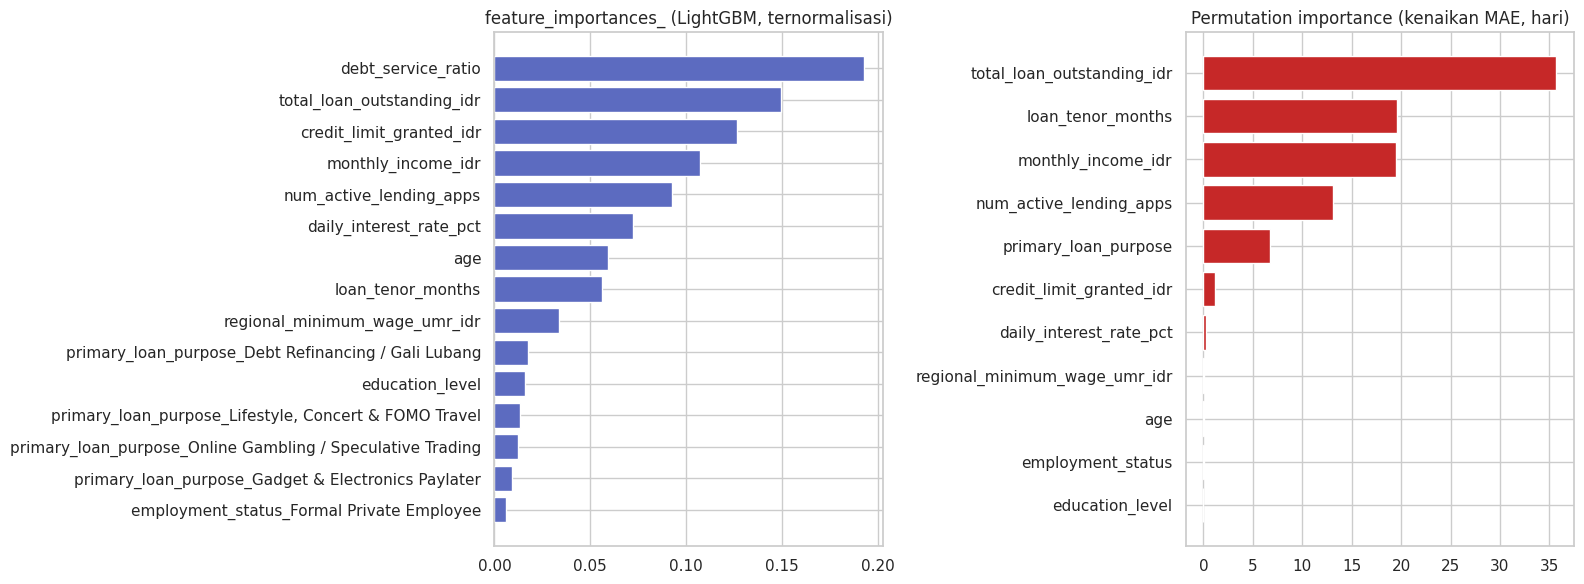

2 detik


total_loan_outstanding_idr       35.71
loan_tenor_months                19.57
monthly_income_idr               19.48
num_active_lending_apps          13.15
primary_loan_purpose              6.69
credit_limit_granted_idr          1.15
daily_interest_rate_pct           0.23
regional_minimum_wage_umr_idr     0.02
age                               0.02
employment_status                 0.01
education_level                  -0.00
Name: kenaikan MAE (hari), dtype: float64

In [33]:
reg1 = model1['reg'].regressor_
fn1 = model1['prep'].get_feature_names_out()
imp_tree = pd.Series(reg1.feature_importances_, index=[n.split('__', 1)[1] for n in fn1])
imp_tree = (imp_tree / imp_tree.sum()).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(imp_tree.index[-15:], imp_tree.values[-15:], color='#5c6bc0'); axes[0].set_title(f'feature_importances_ ({M1_NAME}, ternormalisasi)')
t0 = time.time()
pi = permutation_importance(model1, X_test, y_test, scoring='neg_mean_absolute_error', n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
pimp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
axes[1].barh(pimp.index, pimp.values, color='#c62828'); axes[1].set_title('Permutation importance (kenaikan MAE, hari)')
plt.tight_layout(); plt.show()
print(f'{time.time() - t0:.0f} detik'); display(pimp.sort_values(ascending=False).round(2).rename('kenaikan MAE (hari)'))

**Insight:**
* **Permutation importance** (kenaikan MAE jika kolom mentah diacak): **pokok utang 35,7 hari**, tenor 19,6, penghasilan 19,5, jumlah aplikasi 13,2, tujuan pinjaman 6,7, limit 1,2. Usia, UMR, pendidikan, dan pekerjaan ≈ 0.
* Tiga kolom teratas (pokok, tenor, penghasilan) adalah **komponen rumus DSR**. Model pada dasarnya belajar dari beban cicilan relatif terhadap penghasilan, ditambah perilaku multi-aplikasi dan tujuan pinjaman. Ini konsisten dengan EDA.
* `feature_importances_` LightGBM (porsi jumlah *split*): **DSR 19,3%**, pokok 14,9%, limit 12,7%, penghasilan 10,7%, aplikasi 9,3%. Namun **usia mendapat 5,9%** padahal permutation importance-nya ≈ 0. Ukuran berbasis split memang cenderung berpihak pada kolom kontinu dengan banyak nilai unik, sehingga permutation importance dan SHAP lebih tepat untuk menjelaskan ke bisnis.

### 8.2 SHAP: faktor pendorong DPD per debitur
`shap.TreeExplainer` menguraikan setiap prediksi menjadi: **nilai dasar (rata-rata prediksi) + kontribusi tiap fitur (dalam hari)**. Kolom one-hot dijumlahkan kembali ke kolom aslinya (`features.top_factors_from_shap`), lalu diambil 3 faktor yang paling **menaikkan** prediksi DPD. Fungsi yang sama dipakai di aplikasi.

Nilai dasar: 51.88 hari | base + Σ SHAP = prediksi (setelah clip): True


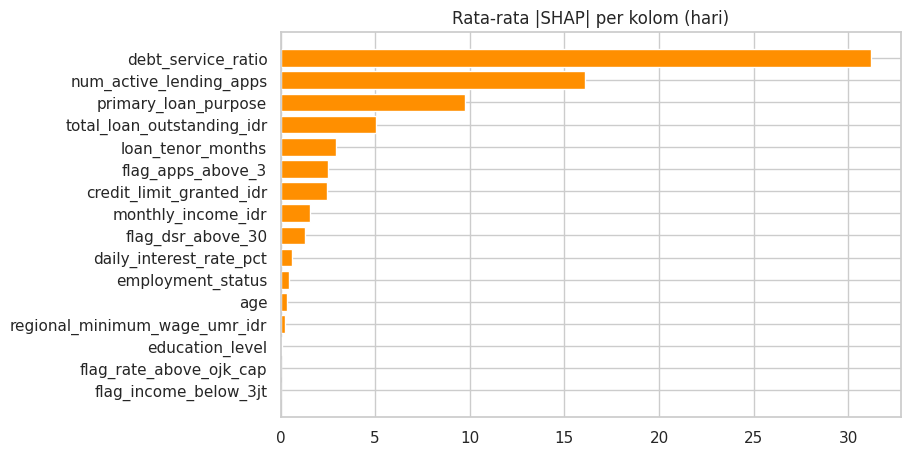


ID_DEB_9E95EC1497 | prediksi 1.9 hari (Lancar) | aktual 0
   + Total pokok utang                 = Rp14,940,000                       +3.7 hari
   + Tenor (bulan)                     = 6                                  +1.2 hari
   + Bunga harian (%)                  = 0.15%                              +0.5 hari

ID_DEB_BFE0846FAD | prediksi 54.6 hari (Kurang Lancar) | aktual 64
   + Rasio cicilan/penghasilan (DSR)   = 160%                               +42.5 hari
   + Penghasilan bulanan               = Rp3,480,000                        +1.9 hari
   + Limit kredit                      = Rp10,190,000                       +1.0 hari

ID_DEB_A8BD2F0773 | prediksi 76.8 hari (Diragukan) | aktual 50
   + Tujuan pinjaman                   = Debt Refinancing / Gali Lubang     +30.4 hari
   + Jumlah aplikasi aktif             = 6                                  +16.2 hari
   + Limit kredit                      = Rp4,270,000                        +7.5 hari

ID_DEB_0D9289463F | prediksi 17

In [34]:
explainer = shap.TreeExplainer(reg1)
Xt_test = model1[:-1].transform(X_test)
Xt_test = Xt_test.toarray() if hasattr(Xt_test, 'toarray') else Xt_test
sv = explainer.shap_values(Xt_test)
check = np.allclose(np.clip(sv.sum(axis=1) + explainer.expected_value, 0, DPD_MAX), p1, atol=0.5)
print(f'Nilai dasar: {float(np.ravel(explainer.expected_value)[0]):.2f} hari | base + Σ SHAP = prediksi (setelah clip): {check}')
shap_abs = pd.Series(np.abs(sv).mean(axis=0), index=[base_feature(n) for n in fn1]).groupby(level=0).sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 5)); ax.barh(shap_abs.index, shap_abs.values, color='#ff8f00')
ax.set_title('Rata-rata |SHAP| per kolom (hari)'); plt.show()

contoh = {}
for kelas in ['Lancar', 'Kurang Lancar', 'Diragukan', 'Macet']:
    pos = np.where(pc_test == kelas)[0][0]; contoh[kelas] = pos
    idx = X_test.index[pos]
    fac = top_factors_from_shap(sv[pos], fn1, X_test.loc[[idx]], top=3)
    print(f"\n{g_test.loc[idx, 'borrower_id']} | prediksi {p1[pos]:.1f} hari ({kelas}) | aktual {y_test[idx]}")
    for f in fac: print(f"   + {f['label']:<33} = {f['nilai']:<34} {f['shap_hari']:+.1f} hari")

**Insight:**
1. Pengecekan: **nilai dasar (51,88 hari) + Σ SHAP = prediksi** untuk semua debitur test. Penjelasannya konsisten dengan prediksi.
2. Rata-rata |SHAP| terbesar ada pada **DSR, jumlah aplikasi, dan tujuan pinjaman**.
3. Contoh:
   * **Macet** (prediksi 178 hari): DSR 155% (+51,8 hari), 7 aplikasi (+30,3), judi (+23,7).
   * **Diragukan** (76,8 hari): gali lubang (+30,4), 6 aplikasi (+16,2).
   * **Kurang Lancar** (54,6 hari): DSR 160% (+42,5).
   * **Lancar** (1,9 hari): faktor penaik kecil (+3,7 hari), karena hampir semua fitur menurunkan prediksinya.
4. Faktor ini berguna untuk tim collection, misalnya untuk menentukan apakah debitur butuh restrukturisasi tenor (DSR tinggi) atau konseling (gali lubang/banyak aplikasi).

### 8.3 Kepatuhan 4 aturan OJK di data test

In [35]:
tf = add_features(X_test); tf['n_pelanggaran'] = tf[FLAG_COLS].sum(axis=1); tf['pred_dpd'] = p1
tf['kolek_pred'] = pd.Categorical(pc_test, COLLECT_ORDER)
display(pd.DataFrame({'melanggar': tf[FLAG_COLS].sum(), '% debitur': (tf[FLAG_COLS].mean() * 100).round(1)}))
display(tf.groupby('n_pelanggaran').agg(debitur=('pred_dpd', 'size'), rata_pred_DPD=('pred_dpd', 'mean')).round(1)
        .join(pd.crosstab(tf['n_pelanggaran'], tf['kolek_pred'])))
print('Debitur test yang mendapat label kepatuhan:', f"{tf[FLAG_COLS].notna().all(axis=1).mean():.0%}")

,melanggar,% debitur
flag_rate_above_ojk_cap,670,33.5
flag_income_below_3jt,336,16.8
flag_apps_above_3,1057,52.8
flag_dsr_above_30,1467,73.4


,debitur,rata_pred_DPD,Lancar,DPK,Kurang Lancar,Diragukan,Macet
n_pelanggaran,,,,,,,
0,144,1.8,137,7,0,0,0
1,643,23.2,333,168,56,35,51
2,801,59.1,170,177,142,96,216
3,363,95.8,29,51,35,36,212
4,49,115.9,0,5,8,1,35


Debitur test yang mendapat label kepatuhan: 100%


**Insight (test, 2.000 debitur):**
* **100% debitur mendapat label kepatuhan** 4 aturan OJK ✅.
* Pola di test sama dengan seluruh data: DSR > 30% 73,4%; > 3 aplikasi 52,8%; bunga di atas batas 33,5%; penghasilan < Rp3 juta 16,8%.
* **144 debitur patuh semua** → rata-rata prediksi DPD **1,8 hari**, dan seluruhnya diprediksi Lancar (137) atau DPK (7). Sebaliknya, 247 dari 412 debitur dengan 3–4 pelanggaran diprediksi Macet.

### 8.4 Fairness (Model 1)
Untuk tiap kelompok dihitung **MAE, RMSE, dan bias** (rata-rata aktual − prediksi; positif berarti model **meremehkan** tunggakan), beserta **jumlah data**. Target: selisih MAE antar gender dan antar pekerjaan ≤ 5 hari. Kelompok dengan < 100 debitur di test ditandai "data sedikit".

Hasil test dicek ulang di **prediksi out-of-fold data train** (n = 8.000) yang lebih stabil. Uji Kruskal-Wallis pada |error| dipakai untuk melihat apakah perbedaan antar kelompok signifikan.

In [36]:
def fairness(col, yt, yp, gframe):
    e = pd.DataFrame({'y': yt.values, 'p': np.asarray(yp), 'g': gframe.loc[yt.index, col].values})
    t = e.groupby('g').apply(lambda d: pd.Series({'n': len(d), 'MAE': mean_absolute_error(d['y'], d['p']),
                                                   'RMSE': np.sqrt(mean_squared_error(d['y'], d['p'])),
                                                   'bias (aktual−pred)': (d['y'] - d['p']).mean()})).sort_values('MAE')
    t['data_sedikit'] = t['n'] < 100
    p = stats.kruskal(*[np.abs(d['y'] - d['p']).values for _, d in e.groupby('g')])[1]
    return t, p

def ringkas(t, p, col, label):
    cukup = t[~t['data_sedikit']]
    gap = cukup['MAE'].max() - cukup['MAE'].min()
    return {'data': label, 'atribut': col, 'selisih MAE (hari)': round(gap, 2), 'p Kruskal |error|': round(p, 3),
            'lolos ≤ 5 hari': gap <= 5}

fair_rows = []
for col in ['gender', 'employment_status', 'province']:
    t, p = fairness(col, y_test, p1, g_test)
    print(f'\n=== TEST — {col} ==='); display(t.round(2))
    fair_rows.append(ringkas(t, p, col, 'test (n=2.000)'))
g_tr = g_train.loc[y_train.index]
for col in ['gender', 'employment_status', 'province']:
    t, p = fairness(col, y_train, oof1, g_tr)
    fair_rows.append(ringkas(t, p, col, 'OOF train (n=8.000)'))
fair_df = pd.DataFrame(fair_rows); display(fair_df)


=== TEST — gender ===


,n,MAE,RMSE,bias (aktual−pred),data_sedikit
g,,,,,
Male,1022.0,8.47,12.25,-0.03,False
Female,978.0,8.48,12.32,-0.46,False



=== TEST — employment_status ===


,n,MAE,RMSE,bias (aktual−pred),data_sedikit
g,,,,,
Civil Servant / BUMN,166.0,7.83,11.67,-0.96,False
Digital Freelancer / Creator,274.0,8.11,11.92,-0.10,False
Entry-Level / Jobseeker,185.0,8.12,11.76,0.98,False
Micro-Entrepreneur / UMKM,245.0,8.12,11.71,-1.23,False
Formal Private Employee,773.0,8.73,12.57,-0.64,False
Gig Worker / Ojol,357.0,8.90,12.85,0.89,False



=== TEST — province ===


,n,MAE,RMSE,bias (aktual−pred),data_sedikit
g,,,,,
Riau,59.0,6.97,11.21,-2.52,True
Lampung,66.0,7.17,11.31,-1.69,True
Sulawesi Selatan,83.0,7.43,11.03,-1.41,True
Kalimantan Timur,41.0,7.83,11.33,-0.46,True
Bali,80.0,7.89,12.85,2.69,True
Jawa Barat,365.0,8.32,12.15,-0.45,False
Banten,242.0,8.41,12.12,0.47,False
DKI Jakarta,474.0,8.66,12.47,-0.12,False
Sumatera Utara,75.0,8.68,12.05,0.56,True


,data,atribut,selisih MAE (hari),p Kruskal |error|,lolos ≤ 5 hari
0,test (n=2.000),gender,0.01,0.948,True
1,test (n=2.000),employment_status,1.07,0.726,True
2,test (n=2.000),province,1.10,0.338,True
3,OOF train (n=8.000),gender,0.19,0.547,True
4,OOF train (n=8.000),employment_status,0.87,0.208,True
5,OOF train (n=8.000),province,1.52,0.625,True


**Insight:**

| Atribut | Selisih MAE (test) | Selisih MAE (OOF train) | p Kruskal (test) | Target ≤ 5 hari |
|---|---|---|---|---|
| **Gender** | **0,01 hari** (8,47 vs 8,48) | 0,19 | 0,948 | ✅ |
| **Pekerjaan** | **1,07 hari** (7,83–8,90) | 0,87 | 0,726 | ✅ |
| Provinsi (kelompok ≥ 100 debitur) | 1,10 hari | 1,52 | 0,338 | ✅ (pelengkap) |

* Tidak ada perbedaan error yang signifikan antar kelompok (semua p > 0,2), baik di test maupun di data OOF yang lebih besar.
* Bias per kelompok kecil (|bias| ≤ 1,3 hari untuk gender dan pekerjaan). Model tidak sistematis meremehkan DPD kelompok tertentu.
* 6 provinsi punya < 100 debitur di test dan ditandai "data sedikit". Selisihnya tidak dijadikan kesimpulan.

**Objective 3 tercapai:** label kepatuhan 100% dan selisih MAE gender/pekerjaan jauh di bawah 5 hari.

## Bab 9 — Artefak & Kesimpulan
### 9.1 Simpan kedua model & metadata

In [37]:
joblib.dump(model1, 'model/model_kelayakan.pkl')
joblib.dump(model2, 'model/model_restrukturisasi.pkl')

def params(s):
    return {k.replace('reg__regressor__', ''): (float(v) if isinstance(v, (float, np.floating)) else (int(v) if isinstance(v, (np.integer,)) else v))
            for k, v in s.best_params_.items()}
metadata = {
    'model_version': 'finguard-r4-v1',
    'model_1': {'file': 'model_kelayakan.pkl', 'algoritma': M1_NAME, 'params': params(m1_search[M1_NAME]),
                'data_latih': 'X_train (semua debitur)', 'cv': {k: round(float(v), 4) for k, v in m1_test.loc['Model 1 (CV)'].items()},
                'test': {k: round(float(v), 4) for k, v in m1_test.loc['Model 1 (test)'].items()},
                'status_test': {k: round(float(v), 4) for k, v in status_scores.items()}},
    'model_2': {'file': 'model_restrukturisasi.pkl', 'algoritma': M2_NAME, 'params': params(m2_search[M2_NAME]),
                'data_latih': 'X_train dengan DPD > 0', 'cv': {k: round(float(v), 4) for k, v in m2_test.loc['Model 2 (CV)'].items()},
                'test': {k: round(float(v), 4) for k, v in m2_test.loc['Model 2 (test)'].items()}},
    'thresholds': THR,
    'input_columns': RAW_INPUT, 'model_num_cols': MODEL_NUM_COLS, 'model_cat_cols': MODEL_CAT_COLS,
    'input_range': {c: {'min': float(X_train[c].min()), 'max': float(X_train[c].max())} for c in RAW_NUM},
    'categories': {c: sorted(X_train[c].unique().tolist()) for c in RAW_CAT},
    'feature_names_out': fn1.tolist(),
    'versions': {'python': platform.python_version(), 'scikit-learn': sklearn.__version__, 'pandas': pd.__version__,
                 'numpy': np.__version__, 'lightgbm': lightgbm.__version__, 'shap': shap.__version__},
    'random_state': RANDOM_STATE,
}
with open('model/model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)
r1, r2m = joblib.load('model/model_kelayakan.pkl'), joblib.load('model/model_restrukturisasi.pkl')
assert np.allclose(predict_dpd(r1, X_test), p1) and np.allclose(predict_dpd(r2m, X2_test), p2)
print('Tersimpan & terverifikasi:', M1_NAME, '|', M2_NAME, '| batas:', THR)

Tersimpan & terverifikasi: LightGBM | LightGBM | batas: {'lancar': 8.0, 'dpk': 30, 'kurang_lancar': 60, 'diragukan': 90}


### 9.2 Kesimpulan

**Jawaban per objective (data test)**

| Objective | Target | Hasil | Status |
|---|---|---|---|
| 1 — Model 1 | MAE ≤ 10, RMSE ≤ 15 hari | **8,47 / 12,29** (LinReg 13,06; Dummy 50,25) | ✅ |
| 1 — Model 2 | MAE ≤ 12 hari | **10,68** (LinReg 15,55; Dummy 49,52) | ✅ |
| 1 — Pelengkap | Recall Macet ≥ 0,90 | **0,945** | ✅ |
| 1 — Dampak | Penurunan debitur kelas tengah → Macet ≥ 35% | 34,7% (cakupan test 69,4%) | ⚠️ meleset tipis (ilustrasi) |
| 2 | Kerugian turun ±Rp3,20 M | Rp3,17 M (ilustrasi) | ≈ |
| 3 | Label OJK 100%; selisih MAE gender & pekerjaan ≤ 5 hari | 100%; 0,01 & 1,07 hari | ✅ |

**Model terpilih:** Model 1 dan Model 2 sama-sama **LightGBM** (MAE CV terendah dan lolos semua syarat).

**Rekomendasi per status**
| Status (prediksi) | Tindakan |
|---|---|
| **Layak** (Lancar ≤ 8 hari, DPK ≤ 30) | Pemantauan rutin / pengingat otomatis |
| **Dalam Pengawasan** (31–90) | Simulasi restrukturisasi: **79% punya opsi tenor aman**; sisanya (umumnya *debt spiral*) → konsolidasi/konseling/eskalasi |
| **Tidak Layak** (> 90) | Collection intensif; tidak layak tambah pinjaman |

**Batasan:**
* Provenance DPD tidak terdokumentasi (narasi LLM menyebut DPD persis).
* Snapshot tanpa tanggal.
* Porsi Macet ±7,5× industri (dihitung dari outstanding).
* Tidak ada kolom jenis produk.
* Hasil simulasi adalah **perubahan prediksi model**, bukan sebab-akibat.
* Angka rupiah adalah ilustrasi berbasis asumsi.

**Pengembangan lanjutan:**
1. Tambahkan riwayat pembayaran untuk memperbaiki kelas tengah.
2. Uji dengan data perusahaan nyata yang punya tanggal (validasi waktu).
3. Kalibrasi simulator dengan hasil restrukturisasi sungguhan.
4. Tambahkan kolom jenis produk supaya aturan OJK bisa diterapkan per produk.